<a href="https://colab.research.google.com/github/2201081101-afk/kamrul/blob/main/MULTI-OBJECTIVE%20ADAPTIVE%20HYBRID%20GENETIC%20ALGORITHM%20WITH%20COST-SENSITIVE%20CLASSICAL%20ML%20FOR%20FAKE%20INSTAGRAM%20PROFILE%20DETECTION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.mlab as mlab
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/dataset/Fake instagram profile detection/Instagram_fake_profile_dataset.csv')
df.head()

,profile pic,nums/length username,fullname words,nums/length fullname,name==username,description length,external URL,private,#posts,#followers,#follows,fake
0,1,0.27,0,0.0,0,53,0,0,32,1000,955,0
1,1,0.00,2,0.0,0,44,0,0,286,2740,533,0
2,1,0.10,2,0.0,0,0,0,1,13,159,98,0
3,1,0.00,1,0.0,0,82,0,0,679,414,651,0
4,1,0.00,2,0.0,0,0,0,1,6,151,126,0


In [ ]:
df.shape

(5000, 12)

In [ ]:
df.describe()

,profile pic,nums/length username,fullname words,nums/length fullname,name==username,description length,external URL,private,#posts,#followers,#follows,fake
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03,5000.000000,5000.00000
mean,0.598200,0.166175,1.212800,0.036068,0.007600,20.997200,0.049600,0.227800,103.331400,5.124435e+04,481.381800,0.50000
std,0.490311,0.194733,0.890435,0.106235,0.086855,33.234706,0.217139,0.419455,377.804886,5.963749e+05,761.530132,0.50005
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.00000
25%,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000e+01,58.000000,0.00000
50%,1.000000,0.089193,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,10.000000,1.450000e+02,242.000000,0.50000
75%,1.000000,0.300410,2.000000,0.000000,0.000000,31.250000,0.000000,0.000000,81.000000,6.960000e+02,591.000000,1.00000
max,1.000000,0.920000,12.000000,1.000000,1.000000,150.000000,1.000000,1.000000,7389.000000,1.533854e+07,7500.000000,1.00000


In [ ]:
print(df.isnull().sum())

profile pic             0
nums/length username    0
fullname words          0
nums/length fullname    0
name==username          0
description length      0
external URL            0
private                 0
#posts                  0
#followers              0
#follows                0
fake                    0
dtype: int64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   profile pic           5000 non-null   int64  
 1   nums/length username  5000 non-null   float64
 2   fullname words        5000 non-null   int64  
 3   nums/length fullname  5000 non-null   float64
 4   name==username        5000 non-null   int64  
 5   description length    5000 non-null   int64  
 6   external URL          5000 non-null   int64  
 7   private               5000 non-null   int64  
 8   #posts                5000 non-null   int64  
 9   #followers            5000 non-null   int64  
 10  #follows              5000 non-null   int64  
 11  fake                  5000 non-null   int64  
dtypes: float64(2), int64(10)
memory usage: 468.9 KB


<Axes: >

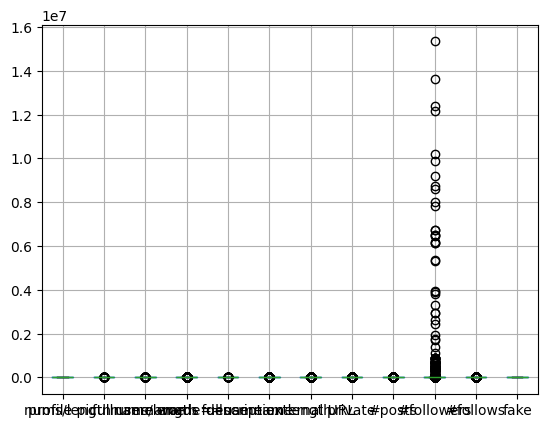

In [ ]:
df.boxplot()

In [ ]:
df['fake'].unique()

array([0, 1])

In [ ]:
conditions = [
    (df['fake'] == 0),
    (df['fake'] == 1)
]
rating = ['real', 'fake']
# Added default='' to ensure all outputs are strings
df['rating'] = np.select(conditions, rating, default='unknown')
fpie=df.rating.value_counts()
print(df.rating.value_counts())

rating
real    2500
fake    2500
Name: count, dtype: int64


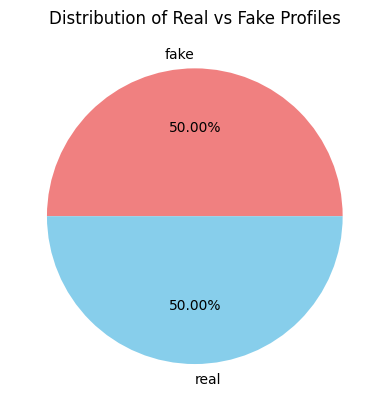

In [ ]:
pi_plot=df.rating.value_counts().sort_index()
plt.pie(pi_plot, labels=['fake', 'real'], colors=['lightcoral', 'skyblue'], autopct='%.2f%%')
plt.title('Distribution of Real vs Fake Profiles')
plt.show()

/tmp/ipykernel_3663/3259661085.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='rating', data=df, palette='viridis')


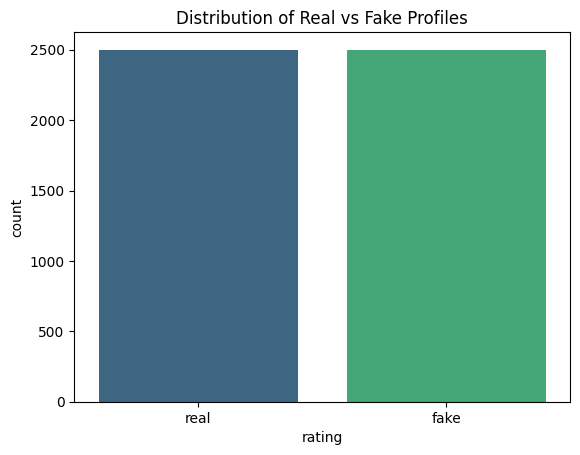

In [ ]:
sns.countplot(x='rating', data=df, palette='viridis')
plt.title('Distribution of Real vs Fake Profiles')
plt.show()

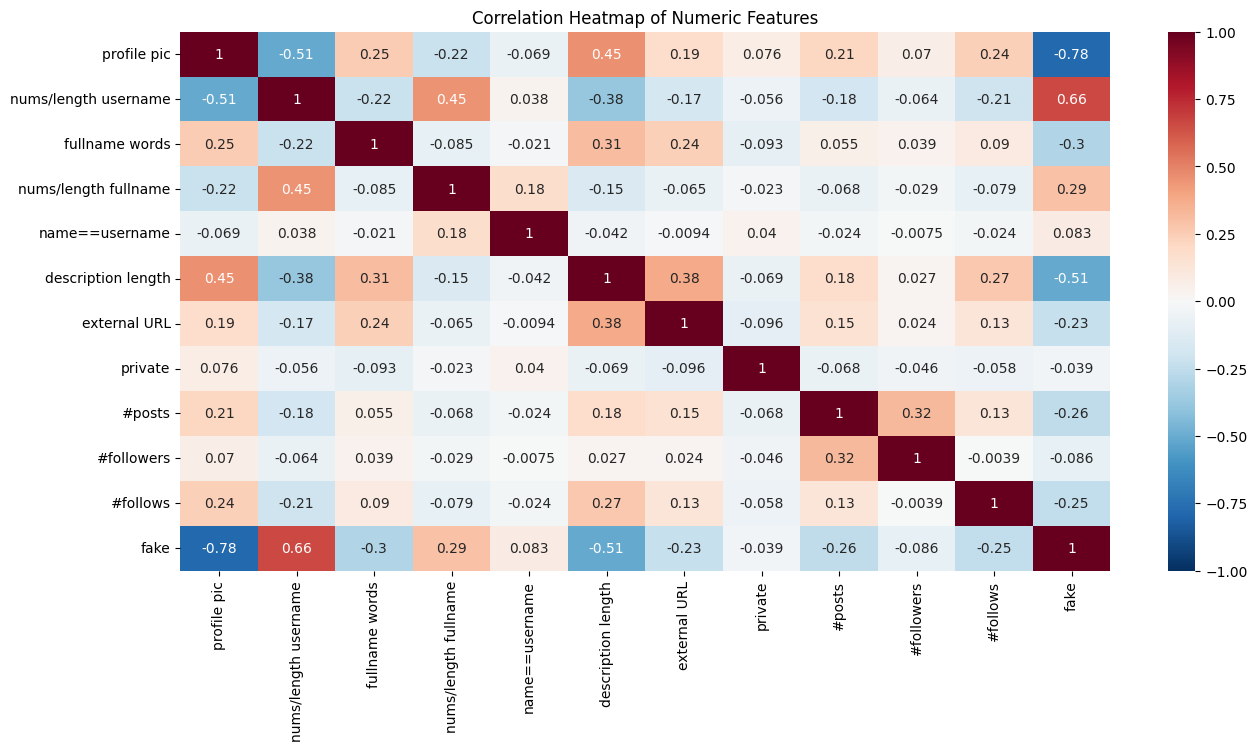

In [ ]:
correlation = df.corr(numeric_only=True)
plt.figure(figsize=(15, 7))
sns.heatmap(correlation, annot=True, linewidths=0, vmin=-1, cmap="RdBu_r")
plt.title('Correlation Heatmap of Numeric Features')
plt.show()

In [ ]:
correlation['fake'].sort_values(ascending=False)

,fake
fake,1.000000
nums/length username,0.663922
nums/length fullname,0.292029
name==username,0.082905
private,-0.038625
#followers,-0.085774
external URL,-0.228448
#follows,-0.245616
#posts,-0.255462
fullname words,-0.302804


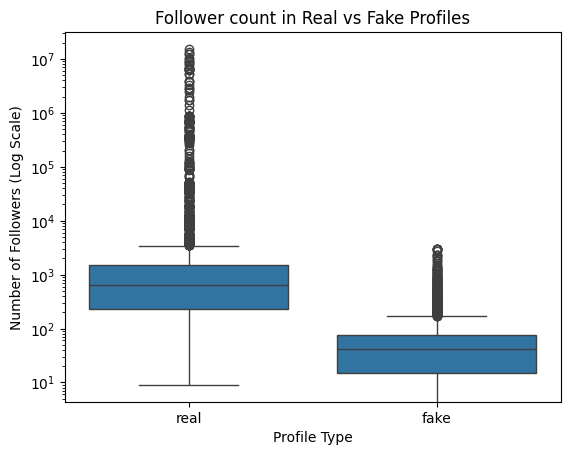

In [ ]:
bxplt = sns.boxplot(x="rating", y='#followers', data = df)
bxplt.set(yscale="log", xlabel='Profile Type', ylabel='Number of Followers (Log Scale)', title='Follower count in Real vs Fake Profiles')
plt.show()

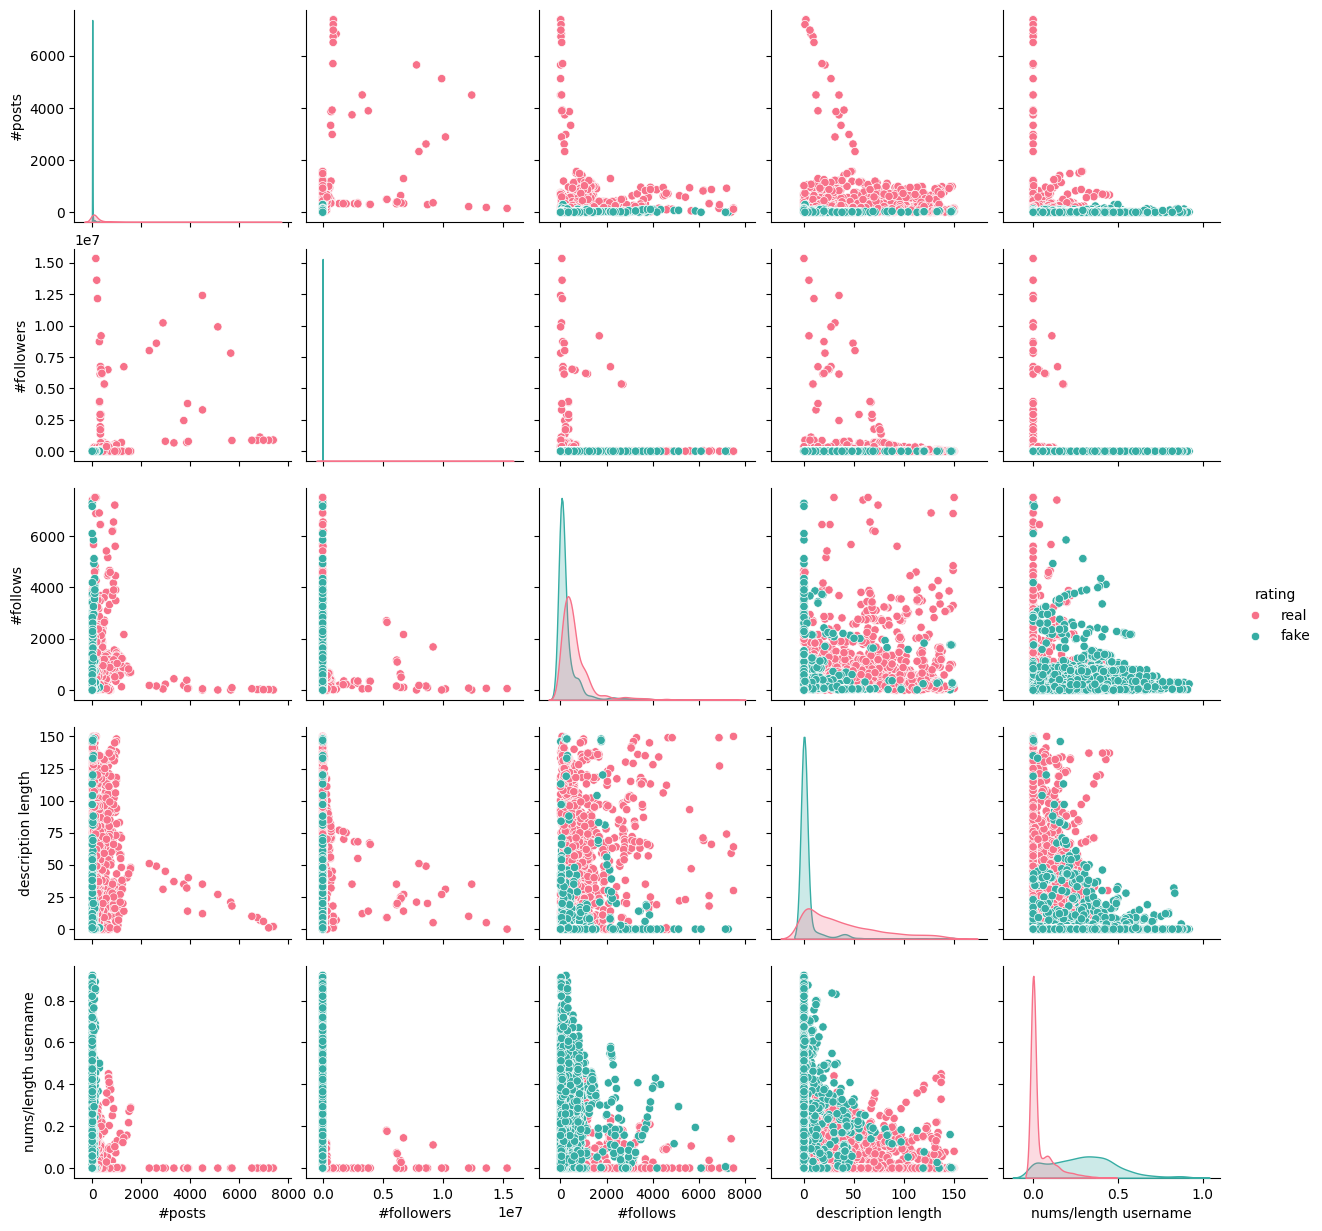

In [ ]:
import seaborn as sns
# Selecting relevant numeric columns from the Instagram dataset
columns_to_plot = ['#posts', '#followers', '#follows', 'description length', 'nums/length username', 'rating']
sns.pairplot(df[columns_to_plot], hue='rating', palette='husl')
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.mlab as mlab
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix,accuracy_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/dataset/Fake instagram profile detection/Instagram_fake_profile_dataset.csv')

In [ ]:
# The 'quality' column does not exist in the Instagram dataset.
# You already created the 'rating' column earlier to label the profiles.
print("Current columns in dataset:", df.columns.tolist())
print("Value counts for target 'fake':")
print(df['fake'].value_counts())

Current columns in dataset: ['profile pic', 'nums/length username', 'fullname words', 'nums/length fullname', 'name==username', 'description length', 'external URL', 'private', '#posts', '#followers', '#follows', 'fake']
Value counts for target 'fake':
fake
0    2500
1    2500
Name: count, dtype: int64


In [ ]:
# The 'quality' column is not part of this dataset.
# The target column is 'fake' (0 = real, 1 = fake).
df['fake'].value_counts()

,count
fake,
0,2500
1,2500


In [ ]:
# Define features (x) and target (y)
# We drop 'fake' because it's the target, and 'rating' because it's a string label
x = df.drop(['fake', 'rating'], axis=1, errors='ignore')
y = df['fake']

# Now perform the train-test split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=5)

print("Features shape:", x.shape)
print("Split complete: x_train size =", len(x_train), ", x_test size =", len(x_test))

Features shape: (5000, 11)
Split complete: x_train size = 3750 , x_test size = 1250


In [ ]:
logreg = LogisticRegression()
logreg.fit(x_train, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [ ]:
print('Coefficients:', logreg.coef_)
print('Intercept:', logreg.intercept_)
predictions = logreg.predict(x_test)
print('Classification Report:\n',classification_report(y_test, predictions))
print('Confusion Matrix:\n',confusion_matrix(y_test, predictions))
print('Accuracy Score:',accuracy_score(y_test, predictions))
print("Precision:",metrics.precision_score(y_test, predictions,average='micro'))
print("Recall:",metrics.recall_score(y_test,predictions,average='micro' ))

Coefficients: [[-4.89162649e+00  4.54980864e+00 -3.28787663e-01  1.13662783e+00
   2.67648416e-01 -7.19087772e-03 -1.63599863e-01 -1.07726303e+00
  -2.01597658e-02 -3.63625086e-03  1.23442569e-03]]
Intercept: [4.99869506]
Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.98      0.96       644
           1       0.98      0.93      0.95       606

    accuracy                           0.96      1250
   macro avg       0.96      0.96      0.96      1250
weighted avg       0.96      0.96      0.96      1250

Confusion Matrix:
 [[632  12]
 [ 43 563]]
Accuracy Score: 0.956
Precision: 0.956
Recall: 0.956


([<matplotlib.axis.YTick at 0x7c57cd78ae10>,
 [Text(0, 0, '0'), Text(0, 1, '1')])

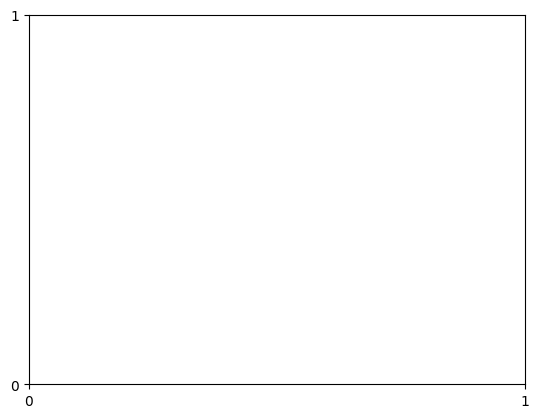

In [ ]:
class_names=[0,1] # name of classes
fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)

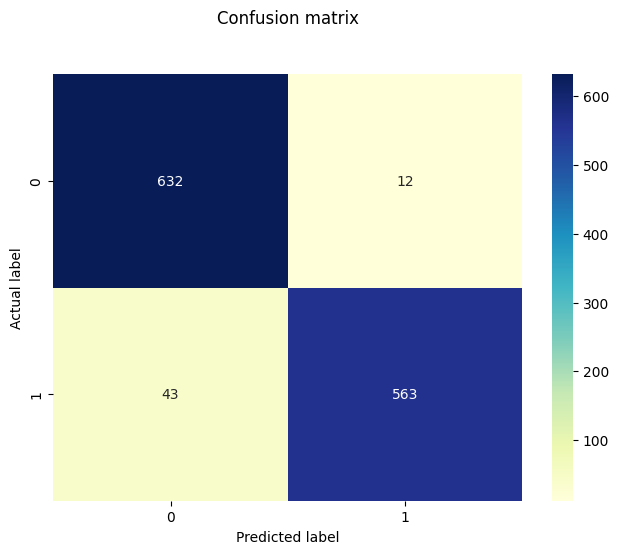

In [ ]:
sns.heatmap(pd.DataFrame(confusion_matrix(y_test, predictions)), annot=True,
cmap="YlGnBu" ,fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()

plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

AUC: 0.9552046819588791


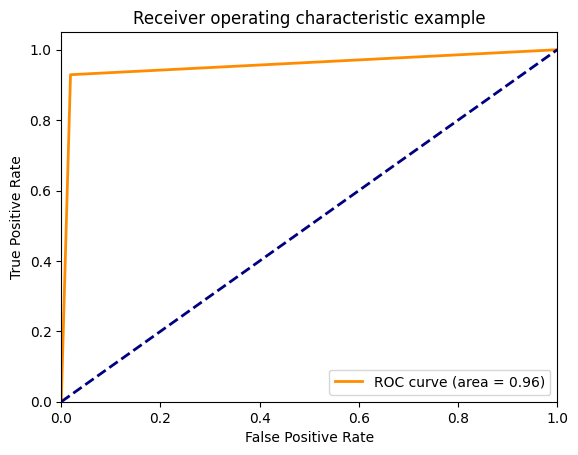

In [ ]:
probs = logreg.predict(x_test)
from sklearn.metrics import roc_curve, roc_auc_score
###Compute the AUC Score.
auc = roc_auc_score(y_test, probs)
print('AUC:', auc)
###Get the ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, probs)
####Plot ROC Curve
plt.figure()
lw = 2
plt.plot(fpr, tpr, color='darkorange',
lw=lw, label='ROC curve (area = %0.2f)' % auc)
plt.plot([0, 1], [0, 1], color='navy', lw=lw, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic example')
plt.legend(loc="lower right")
plt.show()

In [ ]:
from sklearn import tree

# Creating and fitting the Decision Tree Classifier
clf = tree.DecisionTreeClassifier(max_depth=2)
clf = clf.fit(x_train, y_train)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


In [ ]:
y_pred = clf.predict(x_test)
print(classification_report(y_test, y_pred))
print('\nAccuracy: {0:.4f}'.format(accuracy_score(y_test, y_pred)))
predictions = clf.predict(x_test)
print('Confusion Matrix:\n',confusion_matrix(y_test, predictions))

              precision    recall  f1-score   support

           0       0.91      0.95      0.93       644
           1       0.95      0.89      0.92       606

    accuracy                           0.92      1250
   macro avg       0.93      0.92      0.92      1250
weighted avg       0.93      0.92      0.92      1250


Accuracy: 0.9240
Confusion Matrix:
 [[613  31]
 [ 64 542]]


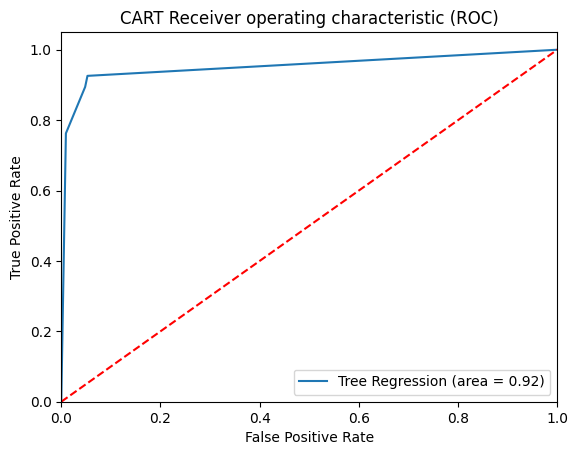

In [ ]:
cart_roc_auc = roc_auc_score(y_test, clf.predict(x_test))
fpr, tpr, thresholds = roc_curve(y_test, clf.predict_proba(x_test)[:,1])
plt.figure()
plt.plot(fpr, tpr, label='Tree Regression (area = %0.2f)' % cart_roc_auc)
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('CART Receiver operating characteristic (ROC)')
plt.legend(loc="lower right")
plt.savefig('Log_ROC')
plt.show()

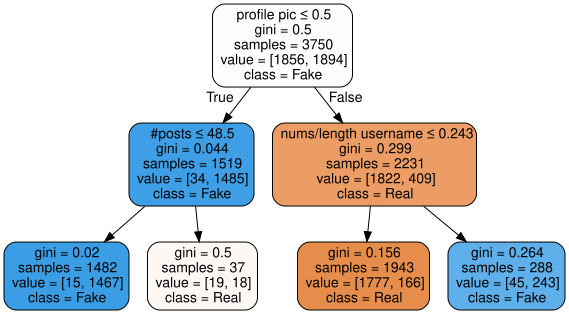

In [ ]:
import graphviz

# Export the tree as DOT data
dot_data = tree.export_graphviz(clf, out_file=None, max_depth=2,
feature_names=x.columns, class_names=['Real','Fake'], filled=True, rounded=True,
special_characters=True)

# Visualize the tree using graphviz
valgTre = graphviz.Source(dot_data)
valgTre

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Creating and fitting the Random Forest Classifier
rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=0)
rf.fit(x_train, y_train)

RandomForestClassifier(max_depth=10, random_state=0)

In [ ]:
y_pred = rf.predict(x_test)
print(classification_report(y_test, y_pred))
print('\nAccuracy: {0:.4f}'.format(accuracy_score(y_test, y_pred)))
print('Confusion Matrix:\n',confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.98      0.99      0.99       644
           1       0.99      0.98      0.99       606

    accuracy                           0.99      1250
   macro avg       0.99      0.99      0.99      1250
weighted avg       0.99      0.99      0.99      1250


Accuracy: 0.9856
Confusion Matrix:
 [[639   5]
 [ 13 593]]


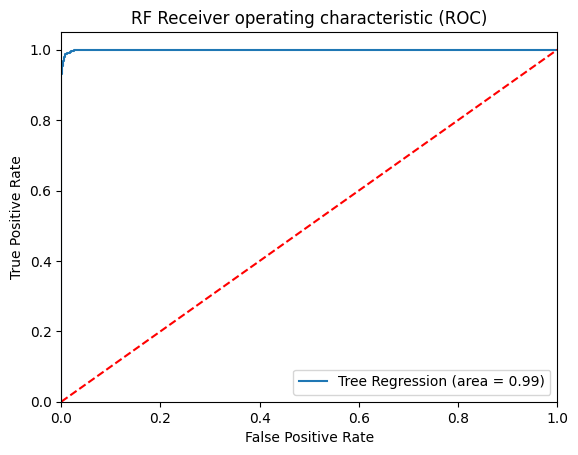

In [ ]:
rf_roc_auc = roc_auc_score(y_test, rf.predict(x_test))
fpr, tpr, thresholds = roc_curve(y_test, rf.predict_proba(x_test)[:,1])
plt.figure()
plt.plot(fpr, tpr, label='Tree Regression (area = %0.2f)' % rf_roc_auc)
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('RF Receiver operating characteristic (ROC)')
plt.legend(loc="lower right")
plt.savefig('RF_ROC')
plt.show()

In [ ]:
from sklearn.svm import SVC

# Initializing and fitting the Support Vector Classifier
svmmdl=SVC()
svmmdl.fit(x_train, y_train)

SVC()

In [ ]:
pred=svmmdl.predict(x_test)
print(classification_report(y_test, pred))
print('\nAccuracy: {0:.4f}'.format(accuracy_score(y_test, pred)))
print(confusion_matrix(y_test,pred))

              precision    recall  f1-score   support

           0       1.00      0.06      0.11       644
           1       0.50      1.00      0.67       606

    accuracy                           0.52      1250
   macro avg       0.75      0.53      0.39      1250
weighted avg       0.76      0.52      0.38      1250


Accuracy: 0.5160
[[ 39 605]
 [  0 606]]


In [ ]:
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression()

In [ ]:
from sklearn import tree
DTclf=tree.DecisionTreeClassifier()

In [ ]:
from sklearn.ensemble import RandomForestClassifier
RFclf=RandomForestClassifier(n_estimators=11)

In [ ]:
from sklearn.svm import SVC
SVclf = SVC(kernel='poly', degree=4)

In [ ]:
from sklearn.model_selection import KFold
# Using x (lowercase) as defined in your previous cells
cv = KFold(n_splits=5, random_state=1, shuffle=True)

for train_index, test_index in cv.split(x):
    print("Train Index: ", train_index)
    print("Test Index: ", test_index)
    # Using .iloc for pandas DataFrame indexing
    X_train, X_test = x.iloc[train_index], x.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

Train Index:  [   0    1    2 ... 4996 4998 4999]
Test Index:  [   5   11   12   13   17   19   21   28   32   37   40   44   45   55
   57   58   62   79   82   86   90   94   98   99  100  102  107  108
  111  115  119  120  123  126  133  134  136  141  157  161  165  169
  181  188  190  191  192  196  200  203  205  206  218  219  221  222
  230  244  246  248  250  256  273  275  276  280  285  299  301  304
  306  313  314  316  322  324  325  329  330  331  335  343  348  349
  358  359  364  366  372  393  394  407  420  428  440  447  448  457
  486  494  501  503  516  517  544  552  553  555  556  557  560  566
  573  574  579  582  587  589  592  599  600  608  610  623  636  643
  644  645  646  662  678  684  685  687  694  700  703  717  718  724
  729  745  748  749  756  757  758  759  761  763  770  771  772  779
  783  789  791  792  795  796  799  804  808  823  834  836  839  854
  858  863  870  871  874  881  885  891  895  898  899  901  906  910
  921  927  93

In [ ]:
# Initialize the list to store scores if it doesn't exist
if 'LoGscores' not in locals():
    LoGscores = []

# Fit the model and store the score
logreg.fit(X_train, y_train)
LoGscores.append(logreg.score(X_test, y_test))

print(f"Current CV Score: {LoGscores[-1]:.4f}")

Current CV Score: 0.9520


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
# Initialize the list to store Decision Tree scores if it doesn't exist
if 'DTscores' not in locals():
    DTscores = []

# Fit the model and store the score
DTclf.fit(X_train, y_train)
DTscores.append(DTclf.score(X_test, y_test))

print(f"Current DT CV Score: {DTscores[-1]:.4f}")

Current DT CV Score: 0.9710


In [ ]:
# Initialize the list to store Random Forest scores if it doesn't exist
if 'RFscores' not in locals():
    RFscores = []

# Fit the model and store the score
RFclf.fit(X_train, y_train)
RFscores.append(RFclf.score(X_test, y_test))

print(f"Current RF CV Score: {RFscores[-1]:.4f}")

Current RF CV Score: 0.9850


In [ ]:
# Initialize the list to store SVM scores if it doesn't exist
if 'SVscores' not in locals():
    SVscores = []

# Fit the model and store the score
SVclf.fit(X_train, y_train)
SVscores.append(SVclf.score(X_test, y_test))

print(f"Current SV CV Score: {SVscores[-1]:.4f}")

Current SV CV Score: 0.5110


In [ ]:
import numpy as np
print('Logistic Reg. scores:', np.mean(LoGscores))
print('Decision Tree scores:', np.mean(DTscores))
print('Random Forest scores:', np.mean(RFscores))
print('SVM scores:', np.mean(SVscores))

Logistic Reg. scores: 0.952
Decision Tree scores: 0.971
Random Forest scores: 0.985
SVM scores: 0.511


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.mlab as mlab
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix,accuracy_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve

In [ ]:
df= pd.read_csv('/content/drive/MyDrive/dataset/Fake instagram profile detection/Instagram_fake_profile_dataset.csv')

In [ ]:
from sklearn.preprocessing import normalize
data_scaled = normalize(df)
data_scaled = pd.DataFrame(data_scaled, columns=df.columns)
data_scaled.head()

,profile pic,nums/length username,fullname words,nums/length fullname,name==username,description length,external URL,private,#posts,#followers,#follows,fake
0,0.000722,0.000195,0.000000,0.0,0.0,0.038291,0.0,0.000000,0.023119,0.722467,0.689956,0.0
1,0.000356,0.000000,0.000713,0.0,0.0,0.015679,0.0,0.000000,0.101913,0.976368,0.189929,0.0
2,0.005341,0.000534,0.010681,0.0,0.0,0.000000,0.0,0.005341,0.069428,0.849163,0.523384,0.0
3,0.000970,0.000000,0.000970,0.0,0.0,0.079534,0.0,0.000000,0.658583,0.401551,0.631425,0.0
4,0.005082,0.000000,0.010164,0.0,0.0,0.000000,0.0,0.005082,0.030492,0.767388,0.640337,0.0


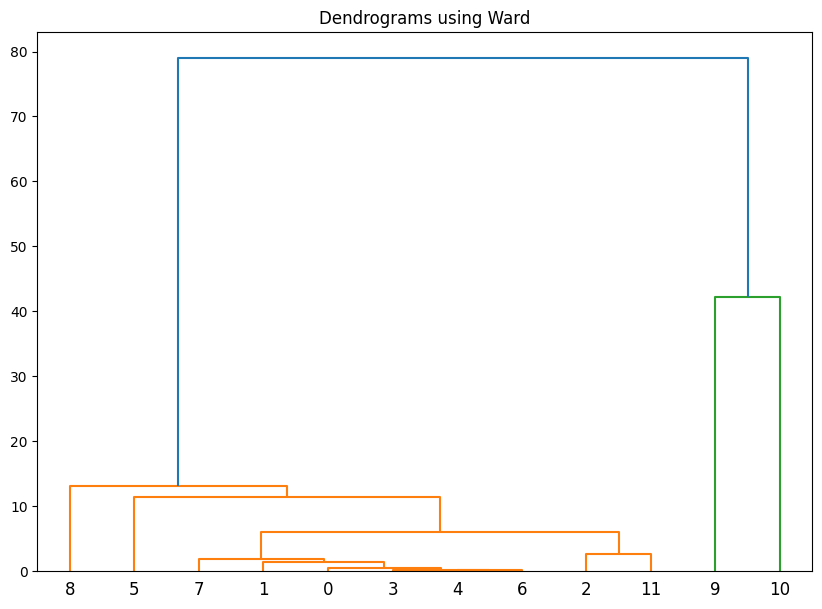

In [ ]:
import scipy.cluster.hierarchy as shc
data_scaled=data_scaled.transpose()
plt.figure(figsize=(10, 7))
plt.title("Dendrograms using Ward")
dend = shc.dendrogram(shc.linkage(data_scaled, method='ward'))
plt.show()

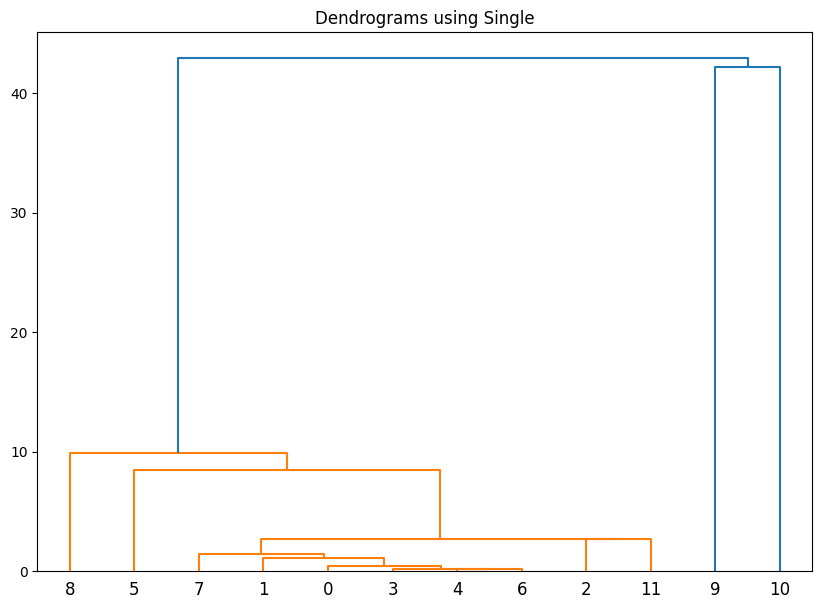

In [ ]:
plt.figure(figsize=(10, 7))
plt.title("Dendrograms using Single")
dend = shc.dendrogram(shc.linkage(data_scaled, method='single'))
plt.show()

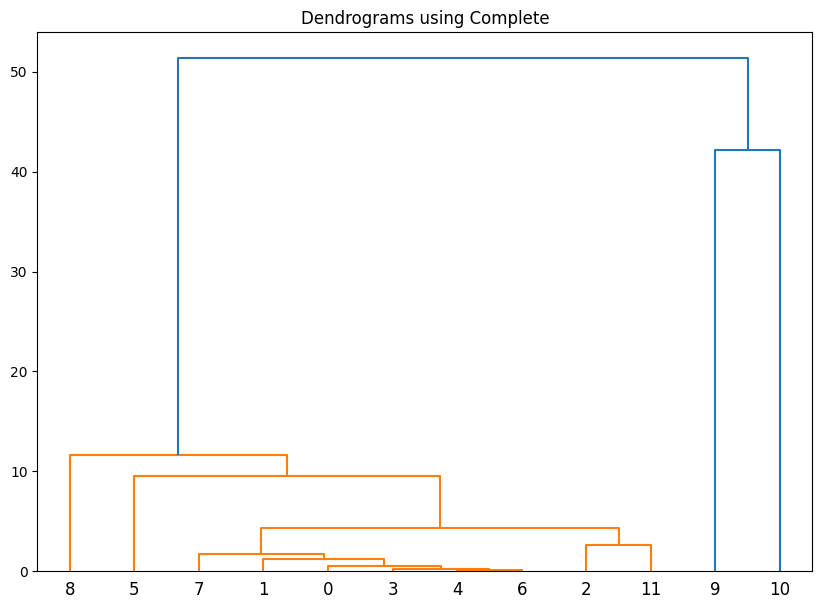

In [ ]:
plt.figure(figsize=(10, 7))
plt.title("Dendrograms using Complete")
dend = shc.dendrogram(shc.linkage(data_scaled, method='complete'))
plt.show()

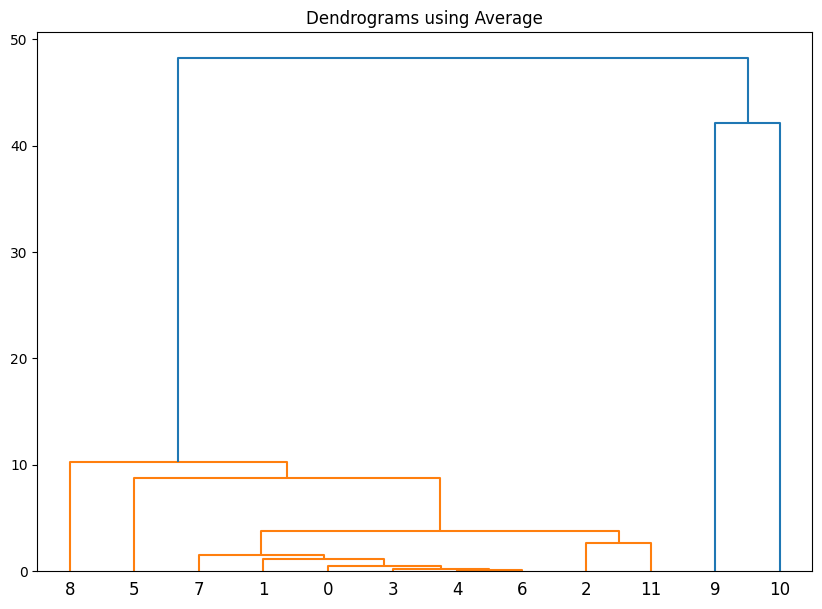

In [ ]:
plt.figure(figsize=(10, 7))
plt.title("Dendrograms using Average")
dend = shc.dendrogram(shc.linkage(data_scaled, method='average'))
plt.show()

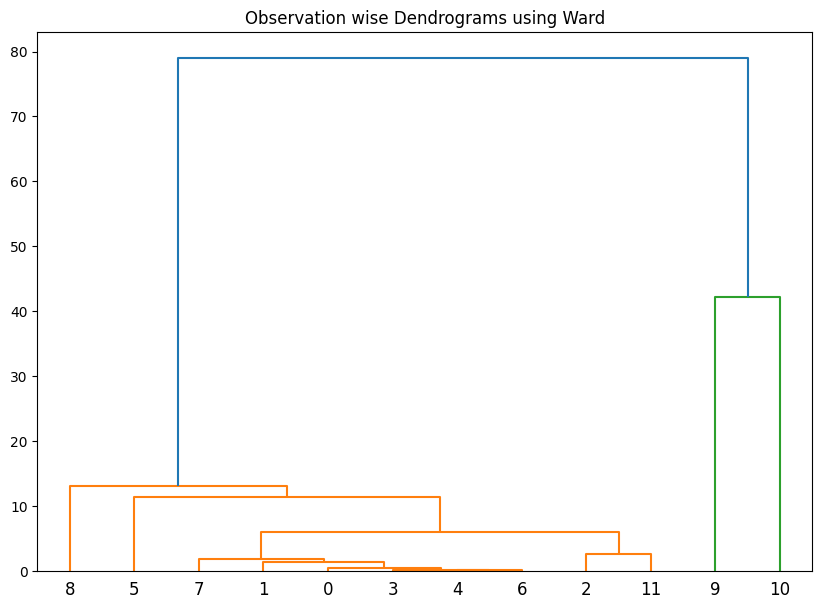

In [ ]:
plt.figure(figsize=(10, 7))
plt.title("Observation wise Dendrograms using Ward")
dend = shc.dendrogram(shc.linkage(data_scaled, method='ward'))
plt.show()

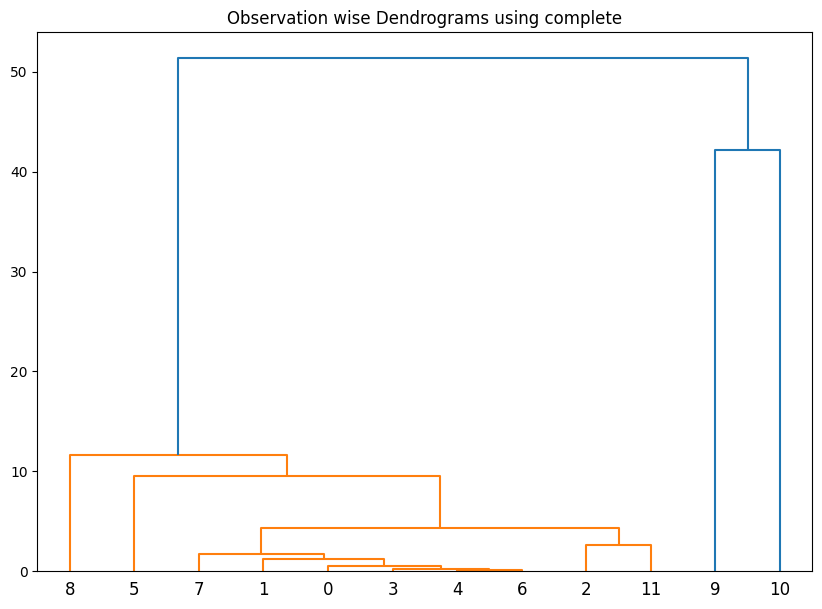

In [ ]:
plt.figure(figsize=(10, 7))
plt.title("Observation wise Dendrograms using complete")
dend = shc.dendrogram(shc.linkage(data_scaled, method='complete'))
plt.show()

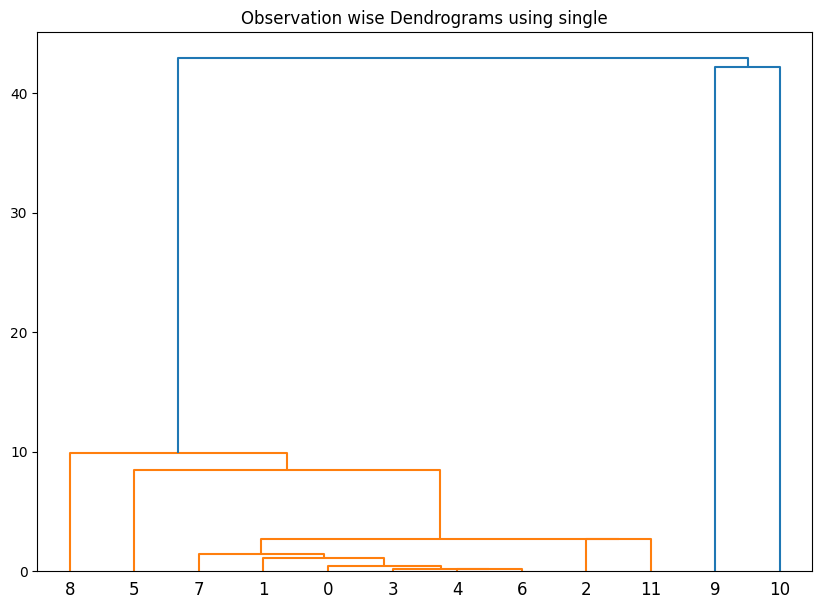

In [ ]:
plt.figure(figsize=(10, 7))
plt.title("Observation wise Dendrograms using single")
dend = shc.dendrogram(shc.linkage(data_scaled, method='single'))
plt.show()

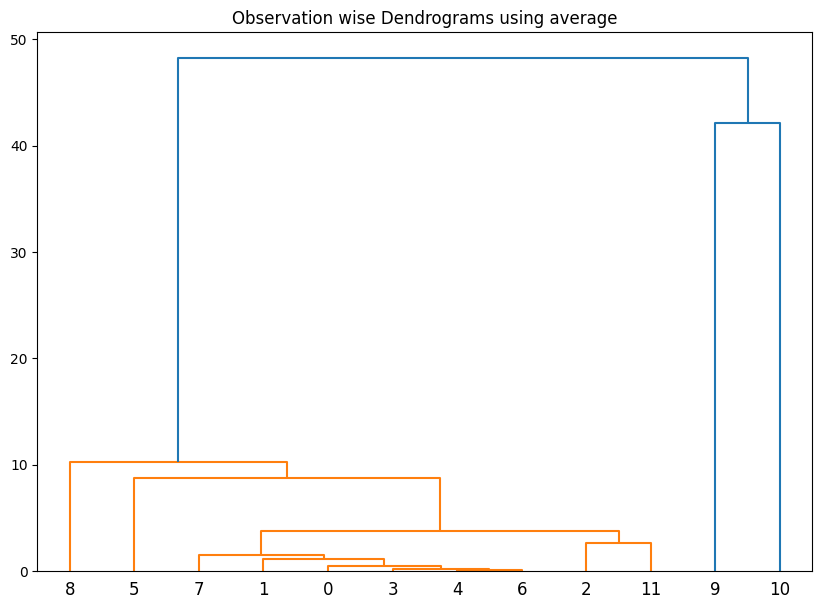

In [ ]:
plt.figure(figsize=(10, 7))
plt.title("Observation wise Dendrograms using average")
dend = shc.dendrogram(shc.linkage(data_scaled, method='average'))
plt.show()

In [ ]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize

# Ensure df is loaded and data_scaled is created in the correct format for KMeans
df = pd.read_csv('/content/drive/MyDrive/dataset/Fake instagram profile detection/Instagram_fake_profile_dataset.csv')
data_scaled = normalize(df)
data_scaled = pd.DataFrame(data_scaled, columns=df.columns)

kmeans = KMeans(n_clusters=5, random_state=42) # Added random_state for reproducibility
kmeans.fit(data_scaled)
print(kmeans.cluster_centers_)
y_km = kmeans.fit_predict(data_scaled)

[[2.36867786e-03 2.35239831e-03 9.20282722e-03 4.00944419e-04
  1.38702980e-04 2.86869659e-02 2.53331693e-05 5.49214866e-04
  1.14373012e-01 7.80926213e-01 5.75803135e-01 7.09992492e-03]
 [2.23306399e-03 3.88310516e-03 1.14838750e-02 6.53871309e-04
  1.54085589e-04 7.38354535e-03 2.91347542e-06 4.42226228e-03
  2.98313431e-02 1.92289477e-01 9.68347557e-01 1.49394031e-02]
 [4.38708449e-04 5.22296364e-03 1.94297792e-02 7.38578480e-04
  9.75212987e-05 1.31066554e-02 4.83308241e-05 1.40500441e-05
  3.24945651e-02 9.76748748e-01 1.28583779e-01 1.79986789e-02]
 [7.77833592e-03 1.51927510e-02 6.59195444e-02 6.26674575e-04
  2.96367567e-04 5.57446498e-01 7.18971369e-05 2.62269211e-02
  1.32280848e-01 2.41389366e-01 5.22098298e-01 1.01188182e-01]
 [2.17368542e-03 2.41247903e-03 9.21952919e-03 4.24414238e-04
  1.43589952e-04 4.08756399e-02 2.69995365e-05 1.67865018e-03
  8.98494500e-02 5.40415159e-01 8.13088303e-01 7.36343749e-03]]


In [ ]:
import torch
import torch.nn as nn
import math

class FeatureTokenizer(nn.Module):
    def __init__(self, num_numerical: int, cat_cardinalities: list[int], d_model: int):
        super().__init__()
        # 1. Numerical Tokenization: Each numerical feature gets its own linear projection weight
        self.num_biases = nn.Parameter(torch.zeros(num_numerical, d_model))
        self.num_weights = nn.Parameter(torch.zeros(num_numerical, d_model))

        # 2. Categorical Tokenization: Standard embeddings for each categorical column
        self.cat_embeddings = nn.ModuleList([
            nn.Embedding(cardinality, d_model) for cardinality in cat_cardinalities
        ])

        # Initialize weights properly
        nn.init.kaiming_uniform_(self.num_weights, a=math.sqrt(5))

    def forward(self, x_num: torch.Tensor, x_cat: torch.Tensor) -> torch.Tensor:
        tokens = []

        # Process numerical features: x_num shape -> (batch_size, num_numerical)
        if x_num is not None and x_num.shape[1] > 0:
            # Multi-field linear projection: x * W + b elementwise across features
            # shape: (batch_size, num_numerical, d_model)
            x_num_tokens = x_num.unsqueeze(-1) * self.num_weights.unsqueeze(0) + self.num_biases.unsqueeze(0)
            tokens.append(x_num_tokens)

        # Process categorical features: x_cat shape -> (batch_size, num_categorical)
        if x_cat is not None and x_cat.shape[1] > 0:
            x_cat_tokens = torch.stack([
                emb(x_cat[:, i]) for i, emb in enumerate(self.cat_embeddings)
            ], dim=1) # shape: (batch_size, num_categorical, d_model)
            tokens.append(x_cat_tokens)

        # Concatenate features along the sequence length dimension
        return torch.cat(tokens, dim=1)

class FTTransformer(nn.Module):
    def __init__(self,
                 num_numerical: int,
                 cat_cardinalities: list[int],
                 d_model: int = 32,
                 nhead: int = 4,
                 num_layers: int = 3,
                 dim_feedforward: int = 64,
                 dropout: float = 0.1,
                 out_dim: int = 1):
        super().__init__()

        # Feature Tokenizer
        self.tokenizer = FeatureTokenizer(num_numerical, cat_cardinalities, d_model)

        # Special CLS token prepended to collect global representation
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_model))
        nn.init.normal_(self.cls_token, std=0.02)

        # Transformer Backbone (using Pre-LayerNorm configuration for stability)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation='gelu',
            batch_first=True,
            norm_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        # Final prediction head
        self.ln_final = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, out_dim)

    def forward(self, x_num: torch.Tensor, x_cat: torch.Tensor) -> torch.Tensor:
        batch_size = x_num.shape[0] if x_num is not None else x_cat.shape[0]

        # 1. Tokenize features -> (batch_size, num_features, d_model)
        x = self.tokenizer(x_num, x_cat)

        # 2. Prepend CLS token -> (batch_size, num_features + 1, d_model)
        cls_tokens = self.cls_token.expand(batch_size, -1, -1)
        x = torch.cat([cls_tokens, x], dim=1)

        # 3. Pass through Transformer
        x = self.transformer(x)

        # 4. Extract CLS token state and predict
        cls_output = x[:, 0, :]
        cls_output = self.ln_final(cls_output)

        return self.head(cls_output)

# --- Example Usage ---
if __name__ == "__main__":
    # Suppose we have 4 numerical features and 2 categorical features (with 3 and 5 unique categories respectively)
    batch_size = 8
    num_features = 4
    cat_cardinalities = [3, 5]

    # Fake batch data
    dummy_num = torch.randn(batch_size, num_features)
    dummy_cat = torch.randint(0, 3, (batch_size, 2)) # Ensure values match cardinalities

    # Initialize FT-Transformer for Binary Classification (out_dim=1)
    model = FTTransformer(
        num_numerical=num_features,
        cat_cardinalities=cat_cardinalities,
        d_model=64,
        nhead=4,
        num_layers=3
    )

    output = model(dummy_num, dummy_cat)
    print("Output shape:", output.shape)  # Expecting: torch.Size([8, 1])

/tmp/ipykernel_537/1956586628.py:69: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


Output shape: torch.Size([8, 1])


In [ ]:
import torch
import torch.nn as nn

class MLP(nn.Module):
    """Standard Multi-Layer Perceptron for the final prediction head."""
    def __init__(self, input_dim: int, hidden_dims: list[int], output_dim: int, dropout: float = 0.1):
        super().__init__()
        layers = []
        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(input_dim, hidden_dim))
            layers.append(nn.ReLU()) # Standard activation for TabTransformer MLP
            layers.append(nn.Dropout(dropout))
            input_dim = hidden_dim

        layers.append(nn.Linear(input_dim, output_dim))
        self.mlp = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.mlp(x)


class TabTransformer(nn.Module):
    def __init__(self,
                 cat_cardinalities: list[int],
                 num_continuous: int,
                 dim: int = 32,
                 depth: int = 4,
                 heads: int = 4,
                 mlp_hidden_dims: list[int] = [128, 64],
                 out_dim: int = 1,
                 dropout: float = 0.1):
        super().__init__()

        # 1. Categorical Branch: Embeddings for each discrete feature
        self.cat_embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dim) for cardinality in cat_cardinalities
        ])

        # 2. Transformer Encoder for categorical embeddings
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=dim,
            nhead=heads,
            dim_feedforward=dim * 4,
            dropout=dropout,
            activation='gelu',
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=depth)

        # 3. Continuous Branch: Bypasses transformer, uses LayerNorm
        self.num_continuous = num_continuous
        if num_continuous > 0:
            self.cont_norm = nn.LayerNorm(num_continuous)

        # 4. Final MLP Head
        # Input size = (number of categorical features * embedding dim) + number of continuous features
        mlp_input_dim = (len(cat_cardinalities) * dim) + num_continuous
        self.mlp = MLP(mlp_input_dim, mlp_hidden_dims, out_dim, dropout)

    def forward(self, x_cat: torch.Tensor, x_cont: torch.Tensor) -> torch.Tensor:
        # --- Process Categorical Features ---
        if x_cat is not None and x_cat.shape[1] > 0:
            # Look up embeddings for each categorical column
            x_cat_emb = [emb(x_cat[:, i]) for i, emb in enumerate(self.cat_embeddings)]
            x_cat_emb = torch.stack(x_cat_emb, dim=1) # Shape: (Batch, Num_Categorical, Dim)

            # Pass through Transformer to get contextual embeddings
            x_cat_emb = self.transformer(x_cat_emb)

            # Flatten outputs for the MLP
            x_cat_emb = x_cat_emb.flatten(1) # Shape: (Batch, Num_Categorical * Dim)
        else:
            x_cat_emb = torch.zeros((x_cont.shape[0], 0), device=x_cont.device)

        # --- Process Continuous Features ---
        if x_cont is not None and self.num_continuous > 0:
            # Simple layer normalization for continuous features
            x_cont_norm = self.cont_norm(x_cont)
        else:
            x_cont_norm = torch.zeros((x_cat.shape[0], 0), device=x_cat.device)

        # --- Combine and Predict ---
        # Concatenate flattened categorical embeddings and normalized continuous features
        x = torch.cat([x_cat_emb, x_cont_norm], dim=1)

        return self.mlp(x)


# ==========================================
# Example: Instagram Fake Profile Detection
# ==========================================
if __name__ == "__main__":
    batch_size = 16

    # 1. Define Categorical Features (Binary flags)
    # has_profile_pic (0/1), is_private (0/1), has_external_url_in_bio (0/1)
    cat_cardinalities = [2, 2, 2]

    # 2. Define Continuous Features
    # num_followers, num_following, num_posts, username_length, bio_length, digit_count_in_username
    num_continuous = 6

    # --- Generate Dummy Instagram Data ---
    # Random integers 0 or 1 for the binary categorical features
    dummy_cat = torch.randint(0, 2, (batch_size, len(cat_cardinalities)))

    # Random floats representing standardized (scaled) continuous features
    # Note: Always apply StandardScaler or MinMaxScaler to your continuous data before feeding it here!
    dummy_cont = torch.randn(batch_size, num_continuous)

    # --- Initialize Model ---
    model = TabTransformer(
        cat_cardinalities=cat_cardinalities,
        num_continuous=num_continuous,
        dim=32,               # Embedding dimension
        depth=3,              # Number of Transformer blocks
        heads=4,              # Attention heads
        mlp_hidden_dims=[128, 64],
        out_dim=1             # Binary Classification (1 = Fake, 0 = Real)
    )

    # --- Forward Pass ---
    logits = model(dummy_cat, dummy_cont)
    probabilities = torch.sigmoid(logits)

    print("Dummy Categorical shape:", dummy_cat.shape)
    print("Dummy Continuous shape: ", dummy_cont.shape)
    print("Logits shape:           ", logits.shape)
    print("\nPredicted probabilities for first 5 accounts:")
    print(probabilities[:5].detach().numpy())

Dummy Categorical shape: torch.Size([16, 3])
Dummy Continuous shape:  torch.Size([16, 6])
Logits shape:            torch.Size([16, 1])

Predicted probabilities for first 5 accounts:
[[0.48543853]
 [0.48059198]
 [0.4747356 ]
 [0.4963467 ]
 [0.47450522]]


In [ ]:
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
!pip install pytorch-tabnet
from pytorch_tabnet.tab_model import TabNetClassifier

# ==========================================
# 1. Create Mock Instagram Profile Dataset
# ==========================================
# Real dataset would load from pd.read_csv("instagram_accounts.csv")
np.random.seed(42)
num_samples = 1000

data = {
    # Categorical Features (Strings/Booleans)
    'has_profile_pic': np.random.choice(['Yes', 'No'], size=num_samples, p=[0.85, 0.15]),
    'is_private': np.random.choice(['Private', 'Public'], size=num_samples, p=[0.4, 0.6]),
    'has_external_url': np.random.choice(['Yes', 'No'], size=num_samples, p=[0.2, 0.8]),

    # Continuous Numerical Features
    'num_followers': np.random.exponential(scale=5000, size=num_samples).astype(int),
    'num_following': np.random.exponential(scale=800, size=num_samples).astype(int),
    'num_posts': np.random.poisson(lam=120, size=num_samples),
    'username_length': np.random.randint(5, 30, size=num_samples),
    'digit_count_in_username': np.random.randint(0, 8, size=num_samples),

    # Target Variable (1 = Fake/Bot Profile, 0 = Authentic Profile)
    'is_fake': np.random.choice([0, 1], size=num_samples, p=[0.8, 0.2])
}

df = pd.DataFrame(data)

# Inject synthetic patterns so the network has rules to learn
# Fake bots usually have high digit count, low followers, but high following
df.loc[(df['digit_count_in_username'] > 4) & (df['num_followers'] < 200), 'is_fake'] = 1
df.loc[(df['has_profile_pic'] == 'No') & (df['num_posts'] == 0), 'is_fake'] = 1

# ==========================================
# 2. Preprocessing & Feature Engineering
# ==========================================
features = [col for col in df.columns if col != 'is_fake']
categorical_features = ['has_profile_pic', 'is_private', 'has_external_url']
numerical_features = [col for col in features if col not in categorical_features]

# Label encode categorical columns and track their dims/indexes for TabNet
cat_idxs = []
cat_dims = []

for col in categorical_features:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    # Find the positional index of this categorical column
    cat_idxs.append(df[features].columns.get_loc(col))
    # Track cardinality (number of unique classes)
    cat_dims.append(len(le.classes_))

# Scale numerical columns for smoother network convergence
scaler = StandardScaler()
df[numerical_features] = scaler.fit_transform(df[numerical_features])

# Train / Validation / Test Splits
X = df[features].values
y = df['is_fake'].values

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_valid, X_test, y_valid, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

# ==========================================
# 3. Initialize & Train TabNet Classifier
# ==========================================
# TabNet automatically creates internal embeddings for specified categorical items
clf = TabNetClassifier(
    cat_idxs=cat_idxs,          #
    cat_dims=cat_dims,          #
    cat_emb_dim=[8, 8, 8],      # Embedding dimension for each categorical feature
    n_d=16, n_a=16,             # Width of decision/attention layers (typically 8 to 64)
    n_steps=4,                  # Number of consecutive sequential attention steps
    gamma=1.3,                  # Factor for feature reuse (1.0 to 2.0)
    lambda_sparse=1e-3,         # Sparsity loss coefficient to force selective masking
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=2e-2),
    mask_type='sparsemax'       # 'sparsemax' or 'entmax' for hard feature selection
)

# Fit the classifier
clf.fit(
    X_train=X_train, y_train=y_train,
    eval_set=[(X_valid, y_valid)],
    eval_name=['valid'],
    eval_metric=['auc', 'accuracy'], # Stop early based on validation loss/metrics
    max_epochs=100,
    patience=15,                     # Early stopping if no improvement after 15 epochs
    batch_size=128,
    virtual_batch_size=64            # Size for Ghost Batch Normalization
)

# ==========================================
# 4. Evaluation & Interpretability
# ==========================================
preds = clf.predict(X_test)
probs = clf.predict_proba(X_test)[:, 1]

print(f"\nTest Set Account Predictions (Sample 5 indices): {preds[:5]}")

# TabNet's killer feature: Inherent Feature Importance Extraction
importance = clf.feature_importances_
importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importance
}).sort_values(by='Importance', ascending=False)

print("\n--- Model Feature Importance (How TabNet made its decisions) ---")
print(importance_df.to_string(index=False))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.4 MB/s eta 0:00:00


/usr/local/lib/python3.12/dist-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.69765 | valid_auc: 0.62104 | valid_accuracy: 0.79333 |  0:00:00s
epoch 1  | loss: 0.63993 | valid_auc: 0.59284 | valid_accuracy: 0.77333 |  0:00:00s
epoch 2  | loss: 0.52331 | valid_auc: 0.5679  | valid_accuracy: 0.78667 |  0:00:00s
epoch 3  | loss: 0.51687 | valid_auc: 0.60965 | valid_accuracy: 0.80667 |  0:00:00s
epoch 4  | loss: 0.50543 | valid_auc: 0.57495 | valid_accuracy: 0.80667 |  0:00:01s
epoch 5  | loss: 0.51481 | valid_auc: 0.55435 | valid_accuracy: 0.79333 |  0:00:01s
epoch 6  | loss: 0.50901 | valid_auc: 0.66197 | valid_accuracy: 0.8     |  0:00:01s
epoch 7  | loss: 0.51322 | valid_auc: 0.64706 | valid_accuracy: 0.8     |  0:00:01s
epoch 8  | loss: 0.50248 | valid_auc: 0.62293 | valid_accuracy: 0.78667 |  0:00:01s
epoch 9  | loss: 0.49712 | valid_auc: 0.56953 | valid_accuracy: 0.79333 |  0:00:01s
epoch 10 | loss: 0.47691 | valid_auc: 0.5473  | valid_accuracy: 0.78667 |  0:00:02s
epoch 11 | loss: 0.48279 | valid_auc: 0.52887 | valid_accuracy: 0.78667 |  0

/usr/local/lib/python3.12/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score

# Import Base Models for the Ensemble
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression

# ==========================================
# 1. Generate Synthetic Instagram Profile Data
# ==========================================
np.random.seed(42)
num_samples = 1500

data = {
    # Categorical Features
    'has_profile_pic': np.random.choice(['Yes', 'No'], size=num_samples, p=[0.88, 0.12]),
    'is_private': np.random.choice(['Private', 'Public'], size=num_samples, p=[0.45, 0.55]),
    'has_external_url': np.random.choice(['Yes', 'No'], size=num_samples, p=[0.15, 0.85]),

    # Continuous Numerical Features
    'num_followers': np.random.exponential(scale=3000, size=num_samples).astype(int),
    'num_following': np.random.exponential(scale=900, size=num_samples).astype(int),
    'num_posts': np.random.poisson(lam=80, size=num_samples),
    'username_digit_ratio': np.random.uniform(0.0, 0.8, size=num_samples), # Higher ratio = more likely a bot

    # Label: 1 = Fake Profile, 0 = Authentic Profile
    'is_fake': np.random.choice([0, 1], size=num_samples, p=[0.82, 0.18])
}

df = pd.DataFrame(data)

# Inject explicit bot behaviors so the ensemble has clear rules to learn
# Rule A: Bots with lots of numbers in username and low follower count
df.loc[(df['username_digit_ratio'] > 0.5) & (df['num_followers'] < 150), 'is_fake'] = 1
# Rule B: Massive following spree vs zero posts or profile picture
df.loc[(df['num_following'] > 2000) & (df['has_profile_pic'] == 'No'), 'is_fake'] = 1

# ==========================================
# 2. Preprocessing & Data Pipeline Structure
# ==========================================
X = df.drop('is_fake', axis=1)
y = df['is_fake']

# Segment features by type
categorical_features = ['has_profile_pic', 'is_private', 'has_external_url']
numerical_features = ['num_followers', 'num_following', 'num_posts', 'username_digit_ratio']

# Define preprocessors for different feature types
numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())  # Centers and scales data (critical for Logistic Regression)
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore')) # OHE without collinearity issues
])

# Combine everything into a unified transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# Train / Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# ==========================================
# 3. Define the Ensemble Base Classifiers
# ==========================================
clf1 = LogisticRegression(max_iter=1000, C=0.5, random_state=42)
clf2 = RandomForestClassifier(n_estimators=150, max_depth=8, random_state=42)
clf3 = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)

# Build the Voting Classifier
# Using voting='soft' predicts the class label based on the argmax of the sums of the predicted probabilities
voting_clf = VotingClassifier(
    estimators=[
        ('lr', clf1),
        ('rf', clf2),
        ('gb', clf3)
    ],
    voting='soft',
    weights=[1, 2, 2] # Giving slightly more mathematical weight to the tree ensembles
)

# Put the preprocessor and the voting framework into a final pipeline
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('ensemble', voting_clf)
])

# ==========================================
# 4. Train and Evaluate
# ==========================================
pipeline.fit(X_train, y_train)

# Run Inference
y_pred = pipeline.predict(X_test)
y_probs = pipeline.predict_proba(X_test)[:, 1]

# Display Performance Summary Metrics
print("=== Instagram Bot Detection - Evaluation Metrics ===")
print(classification_report(y_test, y_pred, target_names=['Authentic Profile', 'Fake Profile']))
print(f"ROC AUC Score: {roc_auc_score(y_test, y_probs):.4f}")

=== Instagram Bot Detection - Evaluation Metrics ===
                   precision    recall  f1-score   support

Authentic Profile       0.83      0.99      0.90       238
     Fake Profile       0.82      0.23      0.35        62

         accuracy                           0.83       300
        macro avg       0.83      0.61      0.63       300
     weighted avg       0.83      0.83      0.79       300

ROC AUC Score: 0.6307


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import classification_report, roc_auc_score

# ==========================================
# 1. Generate Synthetic Instagram Profile Data
# ==========================================
np.random.seed(42)
num_samples = 1200

data = {
    # Categorical Columns
    'has_profile_pic': np.random.choice(['Yes', 'No'], size=num_samples, p=[0.90, 0.10]),
    'is_private': np.random.choice(['Private', 'Public'], size=num_samples, p=[0.40, 0.60]),
    'has_external_url': np.random.choice(['Yes', 'No'], size=num_samples, p=[0.12, 0.88]),

    # Continuous Numerical Columns
    'num_followers': np.random.exponential(scale=2500, size=num_samples).astype(int),
    'num_following': np.random.exponential(scale=750, size=num_samples).astype(int),
    'num_posts': np.random.poisson(lam=95, size=num_samples),
    'username_digit_ratio': np.random.uniform(0.0, 0.75, size=num_samples),

    # Class Target: 1 = Bot / Fake Account, 0 = Authentic User
    'is_fake': np.random.choice([0, 1], size=num_samples, p=[0.85, 0.15])
}

df = pd.DataFrame(data)

# Inject standard automated bot behaviors
# Pattern 1: High digit count in name paired with minimal posting footprint
df.loc[(df['username_digit_ratio'] > 0.45) & (df['num_posts'] < 5), 'is_fake'] = 1
# Pattern 2: Empty profile pictures performing mass follow streaks
df.loc[(df['has_profile_pic'] == 'No') & (df['num_following'] > 1500), 'is_fake'] = 1

# ==========================================
# 2. Pipeline Feature Engineering
# ==========================================
X = df.drop('is_fake', axis=1)
y = df['is_fake']

categorical_features = ['has_profile_pic', 'is_private', 'has_external_url']
numerical_features = ['num_followers', 'num_following', 'num_posts', 'username_digit_ratio']

# Transform continuous variables via Z-score scaling
numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

# Direct categorical columns into safe one-hot encodings
categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

# Process both partitions concurrently
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# Execute Train-Test Split with stratification to keep relative bot density uniform
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# ==========================================
# 3. Build & Train the AdaBoost Framework
# ==========================================
# Standard AdaBoost relies on a single-split decision tree (max_depth=1).
# For tabular structures with correlated fields, increasing max_depth to 2 or 3
# allows the weak learners to catch small interaction patterns between variables.
base_estimator = DecisionTreeClassifier(max_depth=2, random_state=42)

adaboost_model = AdaBoostClassifier(
    estimator=base_estimator,
    n_estimators=100,      # Maximum number of weak estimators before stopping
    learning_rate=0.1,     # Shrinks the contribution of each classifier (prevents overfitting)
    random_state=42
)

# Bundle preprocessing steps and the model into a single reproducible pipeline
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', adaboost_model)
])

# Fit the iterative boosting process
pipeline.fit(X_train, y_train)

# ==========================================
# 4. Evaluation and Insights
# ==========================================
y_pred = pipeline.predict(X_test)
y_probs = pipeline.predict_proba(X_test)[:, 1]

print("=== AdaBoost Bot Detection System Performance ===")
print(classification_report(y_test, y_pred, target_names=['Authentic User', 'Fake/Bot Account']))
print(f"ROC AUC Metric Score: {roc_auc_score(y_test, y_probs):.4f}")

# Extract relative feature impact rankings
importance = pipeline.named_steps['model'].feature_importances_

# Fetch the actual post-transform feature column names for clean visualization
encoded_cat_names = pipeline.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(categorical_features)
all_feature_names = list(numerical_features) + list(encoded_cat_names)

importance_df = pd.DataFrame({
    'Feature Column': all_feature_names,
    'Importance Weight': importance
}).sort_values(by='Importance Weight', ascending=False)

print("\n--- AdaBoost Iterative Feature Importance Breakdown ---")
print(importance_df.to_string(index=False))

=== AdaBoost Bot Detection System Performance ===
                  precision    recall  f1-score   support

  Authentic User       0.82      1.00      0.90       247
Fake/Bot Account       0.00      0.00      0.00        53

        accuracy                           0.82       300
       macro avg       0.41      0.50      0.45       300
    weighted avg       0.68      0.82      0.74       300

ROC AUC Metric Score: 0.5244

--- AdaBoost Iterative Feature Importance Breakdown ---
      Feature Column  Importance Weight
username_digit_ratio           0.392262
           num_posts           0.326158
 has_profile_pic_Yes           0.105989
       num_following           0.086357
       num_followers           0.055021
   is_private_Public           0.034212
has_external_url_Yes           0.000000


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score
from xgboost import XGBClassifier

# ==========================================
# 1. Generate Synthetic Instagram Profile Data
# ==========================================
np.random.seed(42)
num_samples = 2000

data = {
    # Categorical Features (Strings)
    'has_profile_pic': np.random.choice(['Yes', 'No'], size=num_samples, p=[0.88, 0.12]),
    'is_private': np.random.choice(['Private', 'Public'], size=num_samples, p=[0.45, 0.55]),
    'has_external_url': np.random.choice(['Yes', 'No'], size=num_samples, p=[0.15, 0.85]),

    # Continuous Numerical Features
    'num_followers': np.random.exponential(scale=4000, size=num_samples).astype(int),
    'num_following': np.random.exponential(scale=950, size=num_samples).astype(int),
    'num_posts': np.random.poisson(lam=75, size=num_samples),
    'username_digit_ratio': np.random.uniform(0.0, 0.85, size=num_samples),

    # Target Variable: 1 = Bot / Fake Profile, 0 = Real User
    'is_fake': np.random.choice([0, 1], size=num_samples, p=[0.80, 0.20])
}

df = pd.DataFrame(data)

# Inject authentic bot patterns for the gradient booster to map
# Pattern 1: Bot scripts with an unusually high density of numbers in the username
df.loc[(df['username_digit_ratio'] > 0.55) & (df['num_followers'] < 100), 'is_fake'] = 1
# Pattern 2: Empty profiles spam-following thousands of accounts
df.loc[(df['has_profile_pic'] == 'No') & (df['num_following'] > 2500), 'is_fake'] = 1

# ==========================================
# 2. Native Categorical Preparation
# ==========================================
# To use XGBoost's native categorical processing, string columns
# MUST be explicitly cast to the pandas 'category' dtype.
categorical_features = ['has_profile_pic', 'is_private', 'has_external_url']
for col in categorical_features:
    df[col] = df[col].astype('category')

# Separate features and target
X = df.drop('is_fake', axis=1)
y = df['is_fake']

# Split data into Train and Evaluation sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# ==========================================
# 3. Instantiate & Train XGBoost Classifier
# ==========================================
# We set enable_categorical=True to instruct XGBoost to use its internal
# experimental partitioning algorithm for categorical features.
model = XGBClassifier(
    n_estimators=200,             # Total decision trees to sequence
    max_depth=5,                  # Max depth per tree (keeps variance under control)
    learning_rate=0.05,           # Step size shrinkage to prevent overfitting
    subsample=0.8,                # Row subsampling ratio for each tree stage
    colsample_bytree=0.8,         # Feature subsampling ratio per split tree
    scale_pos_weight=4.0,         # Adjusts for class imbalance (4:1 Real vs Fake ratio)
    enable_categorical=True,      # Tells XGBoost to handle categorical natively
    random_state=42,
    eval_metric='logloss'
)

# Fit the sequential boosting trees
model.fit(X_train, y_train)

# ==========================================
# 4. Evaluation Metrics & Feature Importance
# ==========================================
y_pred = model.predict(X_test)
y_probs = model.predict_proba(X_test)[:, 1]

print("=== XGBoost Instagram Bot Detector Metrics ===")
print(classification_report(y_test, y_pred, target_names=['Authentic Profile', 'Fake Profile']))
print(f"ROC AUC Score: {roc_auc_score(y_test, y_probs):.4f}")

# Extract relative GBDT structural gain weights
importance = model.feature_importances_
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Gain Weight Importance': importance
}).sort_values(by='Gain Weight Importance', ascending=False)

print("\n--- XGBoost Structural Feature Gain Ranking ---")
print(importance_df.to_string(index=False))

=== XGBoost Instagram Bot Detector Metrics ===
                   precision    recall  f1-score   support

Authentic Profile       0.80      0.74      0.77       318
     Fake Profile       0.23      0.30      0.26        82

         accuracy                           0.65       400
        macro avg       0.52      0.52      0.52       400
     weighted avg       0.69      0.65      0.67       400

ROC AUC Score: 0.5135

--- XGBoost Structural Feature Gain Ranking ---
             Feature  Gain Weight Importance
username_digit_ratio                0.154734
     has_profile_pic                0.150427
       num_followers                0.145082
       num_following                0.143932
    has_external_url                0.139463
           num_posts                0.138056
          is_private                0.128306


In [ ]:
!pip install catboost
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score

# Import the Gradient Boosting Architectures
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# ==========================================
# 1. Generate Synthetic Instagram Profile Data
# ==========================================
np.random.seed(42)
num_samples = 2500

data = {
    # Categorical Features
    'has_profile_pic': np.random.choice(['Yes', 'No'], size=num_samples, p=[0.88, 0.12]),
    'is_private': np.random.choice(['Private', 'Public'], size=num_samples, p=[0.45, 0.55]),
    'has_external_url': np.random.choice(['Yes', 'No'], size=num_samples, p=[0.15, 0.85]),

    # Continuous Numerical Features
    'num_followers': np.random.exponential(scale=3500, size=num_samples).astype(int),
    'num_following': np.random.exponential(scale=900, size=num_samples).astype(int),
    'num_posts': np.random.poisson(lam=85, size=num_samples),
    'username_digit_ratio': np.random.uniform(0.0, 0.80, size=num_samples),

    # Label: 1 = Bot / Fake Profile, 0 = Real User
    'is_fake': np.random.choice([0, 1], size=num_samples, p=[0.80, 0.20])
}

df = pd.DataFrame(data)

# Inject common automated bot injection patterns
df.loc[(df['username_digit_ratio'] > 0.50) & (df['num_followers'] < 150), 'is_fake'] = 1
df.loc[(df['has_profile_pic'] == 'No') & (df['num_following'] > 2000), 'is_fake'] = 1

# Setup categorical groupings
categorical_features = ['has_profile_pic', 'is_private', 'has_external_url']
X = df.drop('is_fake', axis=1)
y = df['is_fake']

# For LightGBM, categorical columns must be explicitly cast to 'category' pandas dtype
X_lgb = X.copy()
for col in categorical_features:
    X_lgb[col] = X_lgb[col].astype('category')

# Train / Test split
X_train_lgb, X_test_lgb, y_train, y_test = train_test_split(X_lgb, y, test_size=0.2, random_state=42, stratify=y)
X_train_cat, X_test_cat, _, _ = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# ==========================================
# 2. LightGBM Implementation (Fastest Ingestion)
# ==========================================
print("\n--- Training LightGBM ---")
lgb_model = LGBMClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=5,
    num_leaves=31,              # Key parameter for leaf-wise tree splitting control
    random_state=42,
    verbose=-1                  # Mutes background log spam
)
lgb_model.fit(X_train_lgb, y_train)

lgb_preds = lgb_model.predict(X_test_lgb)
lgb_probs = lgb_model.predict_proba(X_test_lgb)[:, 1]

# ==========================================
# 3. CatBoost Implementation (Best with Strings)
# ==========================================
print("\n--- Training CatBoost ---")
cat_model = CatBoostClassifier(
    iterations=150,
    learning_rate=0.05,
    depth=5,
    cat_features=categorical_features, # Explicitly tell CatBoost where text columns are
    random_seed=42,
    verbose=0                          # Keeps console clean
)
cat_model.fit(X_train_cat, y_train)

cat_preds = cat_model.predict(X_test_cat)
cat_probs = cat_model.predict_proba(X_test_cat)[:, 1]

# ==========================================
# 4. Performance Comparison Summary
# ==========================================
print("\n=============================================")
print(f"LightGBM ROC-AUC: {roc_auc_score(y_test, lgb_probs):.4f}")
print(f"CatBoost ROC-AUC: {roc_auc_score(y_test, cat_probs):.4f}")
print("=============================================")
print("\nLightGBM Classification Report Summary:")
print(classification_report(y_test, lgb_preds))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 5.2 MB/s eta 0:00:00

--- Training LightGBM ---

--- Training CatBoost ---

LightGBM ROC-AUC: 0.5836
CatBoost ROC-AUC: 0.5899

LightGBM Classification Report Summary:
              precision    recall  f1-score   support

           0       0.79      0.99      0.88       385
           1       0.84      0.14      0.24       115

    accuracy                           0.80       500
   macro avg       0.82      0.57      0.56       500
weighted avg       0.81      0.80      0.73       500



In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score

# Import Competitor Classifiers
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# ==========================================
# 1. Setup Highly Imbalanced Fraud Dataset
# ==========================================
np.random.seed(101)
num_samples = 3000

# Generating data where bots comprise only ~10% of the population
data = {
    'has_profile_pic': np.random.choice(['Yes', 'No'], size=num_samples, p=[0.92, 0.08]),
    'is_private': np.random.choice(['Private', 'Public'], size=num_samples, p=[0.50, 0.50]),
    'has_external_url': np.random.choice(['Yes', 'No'], size=num_samples, p=[0.10, 0.90]),
    'num_followers': np.random.exponential(scale=4000, size=num_samples).astype(int),
    'num_following': np.random.exponential(scale=800, size=num_samples).astype(int),
    'num_posts': np.random.poisson(lam=60, size=num_samples),
    'username_digit_ratio': np.random.uniform(0.0, 0.90, size=num_samples),
    'is_fake': np.random.choice([0, 1], size=num_samples, p=[0.90, 0.10])
}
df = pd.DataFrame(data)

# Inject standard automated bot behaviors
df.loc[(df['username_digit_ratio'] > 0.60) & (df['num_followers'] < 50), 'is_fake'] = 1
df.loc[(df['has_profile_pic'] == 'No') & (df['num_following'] > 3000), 'is_fake'] = 1

# ==========================================
# 2. Preprocessing & Data Splits
# ==========================================
categorical_features = ['has_profile_pic', 'is_private', 'has_external_url']
numerical_features = ['num_followers', 'num_following', 'num_posts', 'username_digit_ratio']

X = df.drop('is_fake', axis=1)
y = df['is_fake']

# Split data (stratified to ensure identical bot distributions across sets)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Unified preprocessor for non-native categorical algorithms
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
    ])

# Pre-transform data for simple models (AdaBoost / Voting)
X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)

# Custom data copy for LightGBM and XGBoost which handle raw dataframes with proper dtypes better
X_train_native = X_train.copy()
X_test_native = X_test.copy()
for col in categorical_features:
    X_train_native[col] = X_train_native[col].astype('category')
    X_test_native[col] = X_test_native[col].astype('category')

# ==========================================
# 3. Define and Initialize Models
# ==========================================
models = {
    "AdaBoost": AdaBoostClassifier(n_estimators=100, learning_rate=0.1, random_state=42),

    "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.05, max_depth=4,
                             enable_categorical=True, eval_metric='logloss', random_state=42),

    "LightGBM": LGBMClassifier(n_estimators=100, learning_rate=0.05, max_depth=4,
                               verbose=-1, random_state=42),

    "Voting Ensemble": VotingClassifier(
        estimators=[
            ('lr', LogisticRegression(max_iter=1000, random_state=42)),
            ('rf', RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)),
            ('gb', LGBMClassifier(n_estimators=100, verbose=-1, random_state=42))
        ], voting='soft'
    )
}

# ==========================================
# 4. Benchmark Loop & Execution
# ==========================================
results = []

for name, model in models.items():
    # Route to transformed matrices or native categorical dataframes based on requirements
    if name in ["XGBoost", "LightGBM"]:
        model.fit(X_train_native, y_train)
        preds = model.predict(X_test_native)
        probs = model.predict_proba(X_test_native)[:, 1]
    else:
        model.fit(X_train_trans, y_train)
        preds = model.predict(X_test_trans)
        probs = model.predict_proba(X_test_trans)[:, 1]

    # Calculate key threat evaluation metrics
    results.append({
        "Model Name": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds),
        "ROC-AUC": roc_auc_score(y_test, probs)
    })

# Convert summary into a readable dashboard
performance_df = pd.DataFrame(results).sort_values(by="ROC-AUC", ascending=False)
print("\n" + "="*65)
print("             INSTAGRAM BOT DETECTION PERFORMANCE SHOWDOWN")
print("="*65)
print(performance_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("="*65)


             INSTAGRAM BOT DETECTION PERFORMANCE SHOWDOWN
     Model Name  Accuracy  Precision  Recall  ROC-AUC
       LightGBM    0.8900     0.6667  0.0299   0.5583
       AdaBoost    0.8883     0.0000  0.0000   0.5282
Voting Ensemble    0.8883     0.0000  0.0000   0.5186
        XGBoost    0.8983     1.0000  0.0896   0.4958


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# ==========================================
# 1. Create Mock Dataset & Preprocess
# ==========================================
np.random.seed(42)
num_samples = 2000

data = {
    # Categorical Columns (Targeted for unique embeddings)
    'has_profile_pic': np.random.choice(['Yes', 'No'], size=num_samples, p=[0.90, 0.10]),
    'is_private': np.random.choice(['Private', 'Public'], size=num_samples, p=[0.45, 0.55]),
    'has_external_url': np.random.choice(['Yes', 'No'], size=num_samples, p=[0.15, 0.85]),

    # Continuous Variables (Targeted for scalar scaling)
    'num_followers': np.random.exponential(scale=3000, size=num_samples).astype(int),
    'num_following': np.random.exponential(scale=850, size=num_samples).astype(int),
    'num_posts': np.random.poisson(lam=70, size=num_samples),
    'username_digit_ratio': np.random.uniform(0.0, 0.80, size=num_samples),

    # Target
    'is_fake': np.random.choice([0, 1], size=num_samples, p=[0.85, 0.15])
}
df = pd.DataFrame(data)

# Inject synthetic patterns for the model to capture
df.loc[(df['username_digit_ratio'] > 0.50) & (df['num_followers'] < 100), 'is_fake'] = 1
df.loc[(df['has_profile_pic'] == 'No') & (df['num_following'] > 2000), 'is_fake'] = 1

# Encoders and Scalers
cat_cols = ['has_profile_pic', 'is_private', 'has_external_url']
num_cols = ['num_followers', 'num_following', 'num_posts', 'username_digit_ratio']

# Map categorical strings to uniform classes [0, 1, 2...]
cat_dims = []
for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    cat_dims.append(len(le.classes_))

# Scale numerical columns (Crucial for Neural Nets to avoid exploding gradients)
scaler = StandardScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])

# Train / Test Split
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['is_fake'])

# ==========================================
# 2. PyTorch Custom Structured Dataset
# ==========================================
class InstagramDataset(Dataset):
    def __init__(self, dataframe):
        self.cat_features = torch.tensor(dataframe[cat_cols].values, dtype=torch.long)
        self.num_features = torch.tensor(dataframe[num_cols].values, dtype=torch.float32)
        self.targets = torch.tensor(dataframe['is_fake'].values, dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, idx):
        return self.cat_features[idx], self.num_features[idx], self.targets[idx]

train_dataset = InstagramDataset(train_df)
test_dataset = InstagramDataset(test_df)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

# ==========================================
# 3. Deep Tabular Neural Network Architecture
# ==========================================
class TabularNN(nn.Module):
    def __init__(self, cat_dims, num_cont_features, emb_drop=0.1, layers=[128, 64], out_sz=1):
        super().__init__()

        # Define an embedding layer for each categorical feature
        # Rule of thumb for embedding dimension size: min(50, cardinality // 2)
        self.embeddings = nn.ModuleList([nn.Embedding(c_dim, min(50, c_dim // 2 + 1)) for c_dim in cat_dims])
        self.emb_drop = nn.Dropout(emb_drop)

        # Calculate total dimension size after flattening categorical embeddings
        total_emb_dim = sum(min(50, c_dim // 2 + 1) for c_dim in cat_dims)

        # Batch Normalization for continuous input
        self.bn_cont = nn.BatchNorm1d(num_cont_features)

        # Build standard sequential funnel architecture
        input_dim = total_emb_dim + num_cont_features
        net_layers = []

        for i in layers:
            net_layers.append(nn.Linear(input_dim, i))
            net_layers.append(nn.ReLU(inplace=True))
            net_layers.append(nn.BatchNorm1d(i))
            net_layers.append(nn.Dropout(0.3))
            input_dim = i

        net_layers.append(nn.Linear(layers[-1], out_sz))
        self.mlp = nn.Sequential(*net_layers)

    def forward(self, x_cat, x_num):
        # 1. Process categorical embeddings
        embs = [emb(x_cat[:, i]) for i, emb in enumerate(self.embeddings)]
        x_c = torch.cat(embs, dim=1)
        x_c = self.emb_drop(x_c)

        # 2. Normalize and drop continuous numerical inputs
        x_n = self.bn_cont(x_num)

        # 3. Merge paths together
        x = torch.cat([x_c, x_n], dim=1)

        # 4. Predict
        return self.mlp(x)

# Initialize deep architecture
model = TabularNN(cat_dims=cat_dims, num_cont_features=len(num_cols))
criterion = nn.BCEWithLogitsLoss() # Built-in numerical stability over raw BCELoss
optimizer = torch.optim.AdamW(model.parameters(), lr=0.005, weight_decay=1e-4)

# ==========================================
# 4. Neural Network Training Loop
# ==========================================
model.train()
epochs = 15

print("Starting Deep Learning Training Loop...")
for epoch in range(epochs):
    epoch_loss = 0
    for x_cat, x_num, y in train_loader:
        optimizer.zero_grad()

        outputs = model(x_cat, x_num)
        loss = criterion(outputs, y)

        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * x_cat.size(0)

    print(f"Epoch {epoch+1:02d}/{epochs} | Total Batch Loss: {epoch_loss/len(train_loader.dataset):.4f}")

# ==========================================
# 5. Model Evaluation Inferences
# ==========================================
model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for x_cat, x_num, y in test_loader:
        logits = model(x_cat, x_num)
        probs = torch.sigmoid(logits) # Squashes output raw values between 0.0 and 1.0

        all_preds.extend(probs.numpy())
        all_targets.extend(y.numpy())

# Convert to arrays to check predictions
all_preds = np.array(all_preds)
all_targets = np.array(all_targets)
binary_preds = (all_preds > 0.5).astype(int)

accuracy = np.mean(binary_preds == all_targets)
print(f"\nTarget Evaluation Set Complete Accuracy: {accuracy * 100:.2f}%")

Starting Deep Learning Training Loop...
Epoch 01/15 | Total Batch Loss: 0.6512
Epoch 02/15 | Total Batch Loss: 0.5230
Epoch 03/15 | Total Batch Loss: 0.4720
Epoch 04/15 | Total Batch Loss: 0.4447
Epoch 05/15 | Total Batch Loss: 0.4598
Epoch 06/15 | Total Batch Loss: 0.4617
Epoch 07/15 | Total Batch Loss: 0.4428
Epoch 08/15 | Total Batch Loss: 0.4478
Epoch 09/15 | Total Batch Loss: 0.4345
Epoch 10/15 | Total Batch Loss: 0.4482
Epoch 11/15 | Total Batch Loss: 0.4484
Epoch 12/15 | Total Batch Loss: 0.4379
Epoch 13/15 | Total Batch Loss: 0.4376
Epoch 14/15 | Total Batch Loss: 0.4370
Epoch 15/15 | Total Batch Loss: 0.4414

Target Evaluation Set Complete Accuracy: 83.75%


In [ ]:
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, roc_auc_score

RANDOM_STATE = 5
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)


In [ ]:
# ------------------------------------------------------------
# 1. Load data (reuse the exact same dataset/columns as Chapter 3)
# ------------------------------------------------------------
df = pd.read_csv('/content/drive/MyDrive/dataset/Fake instagram profile detection/Instagram_fake_profile_dataset.csv')

FEATURES = ['profile pic', 'nums/length username', 'fullname words',
            'nums/length fullname', 'name==username', 'description length',
            'external URL', 'private', '#posts', '#followers', '#follows']
TARGET = 'fake'

RANDOM_STATE = 5

X = df[FEATURES].values
y = df[TARGET].values
N_FEATURES = len(FEATURES)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)

In [ ]:
# ------------------------------------------------------------
# 2. Cost-sensitive fitness evaluator (the "hybrid" link to classical ML)
#    FN_COST > FP_COST because missing a fake profile (letting it through)
#    is judged costlier than a false accusation of a real profile.
# ------------------------------------------------------------
FN_COST = 5.0
FP_COST = 1.0

def cost_sensitive_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    total_cost = FN_COST * fn + FP_COST * fp
    max_cost = FN_COST * (fn + tp) + FP_COST * (fp + tn)
    return 1 - (total_cost / max_cost)   # 1 = perfect, 0 = worst-case cost

def evaluate_subset(mask):
    """5-fold CV cost-sensitive score for one binary feature mask."""
    idx = np.where(mask == 1)[0]
    if len(idx) == 0:
        return 0.0, 0.0
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    scores = []
    for tr_i, va_i in skf.split(X_train, y_train):
        clf = RandomForestClassifier(
            n_estimators=100, max_depth=10, random_state=RANDOM_STATE,
            class_weight={0: 1, 1: FN_COST / FP_COST})
        clf.fit(X_train[tr_i][:, idx], y_train[tr_i])
        pred = clf.predict(X_train[va_i][:, idx])
        scores.append(cost_sensitive_score(y_train[va_i], pred))
    return float(np.mean(scores)), float(np.std(scores))


In [ ]:
# ------------------------------------------------------------
# 3. Multi-objective fitness: maximise cost-sensitive score,
#    minimise number of features used (weighted-sum + Pareto log)
# ------------------------------------------------------------
ALPHA = 0.85   # weight on classification quality
BETA = 0.15    # weight on feature-count parsimony

def fitness(mask):
    perf, _ = evaluate_subset(mask)
    frac_used = mask.sum() / N_FEATURES
    return ALPHA * perf + BETA * (1 - frac_used), perf, mask.sum()


In [ ]:
# ------------------------------------------------------------
# 4. GA operators
# ------------------------------------------------------------
POP_SIZE = 20
N_GENERATIONS = 25
TOURNAMENT_K = 3
BASE_MUTATION = 0.10
ELITISM = 2

def random_individual():
    ind = np.random.randint(0, 2, size=N_FEATURES)
    if ind.sum() == 0:
        ind[np.random.randint(0, N_FEATURES)] = 1
    return ind

def tournament_select(pop, fits):
    idxs = np.random.choice(len(pop), TOURNAMENT_K, replace=False)
    best = max(idxs, key=lambda i: fits[i][0])
    return pop[best].copy()

def uniform_crossover(p1, p2):
    mask = np.random.randint(0, 2, size=N_FEATURES)
    c1 = np.where(mask, p1, p2)
    c2 = np.where(mask, p2, p1)
    return c1, c2

def mutate(ind, rate):
    for i in range(N_FEATURES):
        if random.random() < rate:
            ind[i] = 1 - ind[i]
    if ind.sum() == 0:
        ind[np.random.randint(0, N_FEATURES)] = 1
    return ind


In [ ]:
import numpy as np
import random
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

# ------------------------------------------------------------
# 5. Adaptive Hybrid GA main loop
# ------------------------------------------------------------
population = [random_individual() for _ in range(POP_SIZE)]
history_best_fitness = []
history_mutation_rate = []
stagnant_generations = 0
prev_best = -np.inf
mutation_rate = BASE_MUTATION

for gen in range(N_GENERATIONS):
    fits = [fitness(ind) for ind in population]          # (fitness, perf, n_feat)
    ranked = sorted(zip(population, fits), key=lambda x: x[1][0], reverse=True)
    best_ind, best_fit = ranked[0]

    # --- Adaptive mutation: raise rate if no improvement, else cool down ---
    if best_fit[0] <= prev_best + 1e-4:
        stagnant_generations += 1
    else:
        stagnant_generations = 0
    mutation_rate = min(0.5, BASE_MUTATION + 0.03 * stagnant_generations)
    prev_best = best_fit[0]

    history_best_fitness.append(best_fit[0])
    history_mutation_rate.append(mutation_rate)
    print(f"Gen {gen:02d} | best_fitness={best_fit[0]:.4f} | "
          f"cost_score={best_fit[1]:.4f} | n_features={best_fit[2]} | "
          f"mutation_rate={mutation_rate:.3f}")

    # --- Next generation: elitism + tournament + crossover + mutation ---
    next_pop = [ranked[i][0].copy() for i in range(ELITISM)]
    pop_only = [p for p, _ in ranked]
    fit_only = [f for _, f in ranked]
    while len(next_pop) < POP_SIZE:
        p1 = tournament_select(pop_only, fit_only)
        p2 = tournament_select(pop_only, fit_only)
        c1, c2 = uniform_crossover(p1, p2)
        c1 = mutate(c1, mutation_rate)
        c2 = mutate(c2, mutation_rate)
        next_pop.extend([c1, c2])
    population = next_pop[:POP_SIZE]

Gen 00 | best_fitness=0.9150 | cost_score=0.9481 | n_features=3 | mutation_rate=0.100
Gen 01 | best_fitness=0.9150 | cost_score=0.9481 | n_features=3 | mutation_rate=0.130
Gen 02 | best_fitness=0.9212 | cost_score=0.9715 | n_features=4 | mutation_rate=0.100
Gen 03 | best_fitness=0.9317 | cost_score=0.9677 | n_features=3 | mutation_rate=0.100
Gen 04 | best_fitness=0.9324 | cost_score=0.9686 | n_features=3 | mutation_rate=0.100
Gen 05 | best_fitness=0.9324 | cost_score=0.9686 | n_features=3 | mutation_rate=0.130
Gen 06 | best_fitness=0.9324 | cost_score=0.9686 | n_features=3 | mutation_rate=0.160
Gen 07 | best_fitness=0.9324 | cost_score=0.9686 | n_features=3 | mutation_rate=0.190
Gen 08 | best_fitness=0.9324 | cost_score=0.9686 | n_features=3 | mutation_rate=0.220
Gen 09 | best_fitness=0.9324 | cost_score=0.9686 | n_features=3 | mutation_rate=0.250
Gen 10 | best_fitness=0.9324 | cost_score=0.9686 | n_features=3 | mutation_rate=0.280
Gen 11 | best_fitness=0.9324 | cost_score=0.9686 | n_f

In [ ]:
# ------------------------------------------------------------
# 6. Final best subset -> evaluate once on the held-out test set
# ------------------------------------------------------------
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix

final_fits = [fitness(ind) for ind in population]
best_ind, best_fit = max(zip(population, final_fits), key=lambda x: x[1][0])
selected_idx = np.where(best_ind == 1)[0]
selected_features = [FEATURES[i] for i in selected_idx]
print("\nGA-selected feature subset:", selected_features)

final_clf = RandomForestClassifier(
    n_estimators=100, max_depth=10, random_state=RANDOM_STATE,
    class_weight={0: 1, 1: FN_COST / FP_COST})
final_clf.fit(X_train[:, selected_idx], y_train)
y_pred = final_clf.predict(X_test[:, selected_idx])
y_proba = final_clf.predict_proba(X_test[:, selected_idx])[:, 1]

print("Test Accuracy :", accuracy_score(y_test, y_pred))
print("Test F1-Score  :", f1_score(y_test, y_pred))
print("Test ROC-AUC   :", roc_auc_score(y_test, y_proba))
print("Cost-sensitive score:", cost_sensitive_score(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))


GA-selected feature subset: ['#posts', '#followers', '#follows']
Test Accuracy : 0.9568
Test F1-Score  : 0.957613814756672
Test ROC-AUC   : 0.99180416
Cost-sensitive score: 0.9696
Confusion matrix:
 [[586  39]
 [ 15 610]]


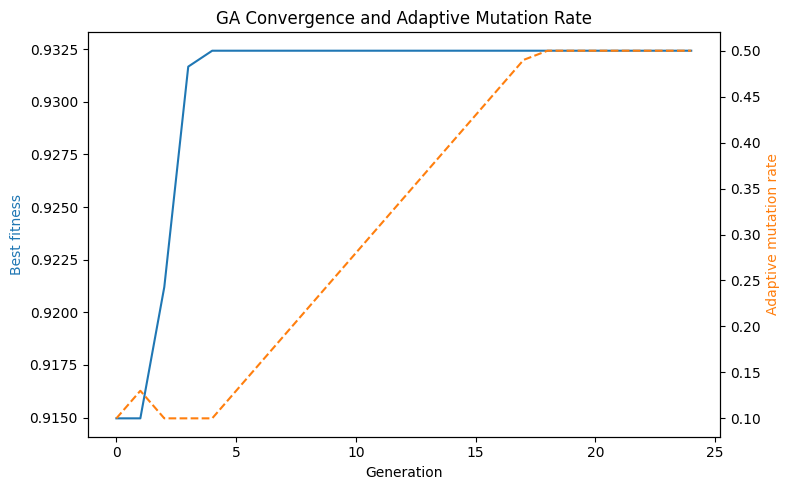

In [ ]:
# ------------------------------------------------------------
# 7. Plot: fitness convergence + adaptive mutation rate
#    (save this figure -> use it as your GA results figure)
# ------------------------------------------------------------
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(history_best_fitness, color="tab:blue", label="Best fitness")
ax1.set_xlabel("Generation")
ax1.set_ylabel("Best fitness", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(history_mutation_rate, color="tab:orange", linestyle="--", label="Mutation rate")
ax2.set_ylabel("Adaptive mutation rate", color="tab:orange")
plt.title("GA Convergence and Adaptive Mutation Rate")
fig.tight_layout()
plt.savefig("ga_convergence.png", dpi=150)
plt.show()

In [ ]:
# ------------------------------------------------------------
# 8. Baseline comparison: all 11 features vs GA-selected subset
#    (use these two rows for your Chapter 4 comparison table)
# ------------------------------------------------------------
baseline_clf = RandomForestClassifier(
    n_estimators=100, max_depth=10, random_state=RANDOM_STATE,
    class_weight={0: 1, 1: FN_COST / FP_COST})
baseline_clf.fit(X_train, y_train)
yb_pred = baseline_clf.predict(X_test)
yb_proba = baseline_clf.predict_proba(X_test)[:, 1]

print("\n--- Comparison ---")
print(f"All 11 features   -> Acc={accuracy_score(y_test, yb_pred):.4f}, "
      f"F1={f1_score(y_test, yb_pred):.4f}, AUC={roc_auc_score(y_test, yb_proba):.4f}")
print(f"GA subset ({len(selected_idx)} feats) -> Acc={accuracy_score(y_test, y_pred):.4f}, "
      f"F1={f1_score(y_test, y_pred):.4f}, AUC={roc_auc_score(y_test, y_proba):.4f}")



--- Comparison ---
All 11 features   -> Acc=0.9856, F1=0.9855, AUC=0.9991
GA subset (3 feats) -> Acc=0.9568, F1=0.9576, AUC=0.9918


In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.ensemble import RandomForestClassifier

# Initialize rf with the baseline configurations
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=5,
    class_weight={0: 1, 1: 5.0}
)

rf.fit(X_train, y_train)          # Use uppercase X_train
tn, fp, fn, tp = confusion_matrix(y_test, rf.predict(X_test)).ravel() # Use uppercase X_test
cs = 1 - (5*fn + fp) / (5*len(y_test))
print(tn, fp, fn, tp, round(cs, 4))

NameError: name 'X_train' is not defined

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load the dataset
df = pd.read_csv('/content/drive/MyDrive/dataset/Fake instagram profile detection/Instagram_fake_profile_dataset.csv')

FEATURES = ['profile pic', 'nums/length username', 'fullname words',
            'nums/length fullname', 'name==username', 'description length',
            'external URL', 'private', '#posts', '#followers', '#follows']
TARGET = 'fake'

RANDOM_STATE = 5

X = df[FEATURES].values
y = df[TARGET].values

# Create train-test splits in uppercase to match your training code
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print("Split complete: X_train shape =", X_train.shape)

Split complete: X_train shape = (3750, 11)


In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score

FN_COST, FP_COST = 5, 1

def cost_sensitive_score(y_true, y_pred, fn_cost=FN_COST, fp_cost=FP_COST):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    cost = fn_cost * fn + fp_cost * fp
    worst = fn_cost * len(y_true)      # normalisation: 5 * N
    return 1 - cost / worst, (tn, fp, fn, tp)

X = df.drop(columns=['fake'])          # all 11 features
y = df['fake']

# Same split as the rest of the thesis (75:25, random_state=5)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=5
)

# Same RF settings as in the GA fitness (use the same random_state as there)
rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)

cs, (tn, fp, fn, tp) = cost_sensitive_score(y_test, pred)
print(f"TN={tn} FP={fp} FN={fn} TP={tp}")
print(f"Accuracy = {accuracy_score(y_test, pred):.4f}")
print(f"F1       = {f1_score(y_test, pred, average='weighted'):.4f}")
print(f"Cost-Sensitive Score (11 features) = {cs:.4f}")

TN=639 FP=5 FN=12 TP=594
Accuracy = 0.9864
F1       = 0.9864
Cost-Sensitive Score (11 features) = 0.9896


In [ ]:
import numpy as np

# Ensure FEATURES and best_ind are mapped correctly
if 'FEATURES' in locals() and 'best_ind' in locals():
    best_chromosome = best_ind
    # Use the FEATURES list to find selected columns directly from best_chromosome
    selected_features = [FEATURES[i] for i, val in enumerate(best_chromosome) if val == 1]
    print(selected_features)
else:
    # Fallback to recreate X and best_ind if they were cleared from memory
    FEATURES = ['profile pic', 'nums/length username', 'fullname words',
                'nums/length fullname', 'name==username', 'description length',
                'external URL', 'private', '#posts', '#followers', '#follows']

    # Re-extract from population best if available, otherwise default to GA subset
    if 'best_ind' in locals():
        best_chromosome = best_ind
    else:
        # From cell foBY5FeMj8EI, the best subset had '#posts', '#followers', '#follows'
        # indices: 8, 9, 10
        best_chromosome = np.zeros(len(FEATURES))
        best_chromosome[[8, 9, 10]] = 1

    selected_features = [FEATURES[i] for i, val in enumerate(best_chromosome) if val == 1]
    print(selected_features)

['#posts', '#followers', '#follows']


In [6]:
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import os

# Ensure y_test and pred are computed
try:
    _ = y_test
    _ = pred
except NameError:
    dataset_path = '/content/drive/MyDrive/dataset/Fake instagram profile detection/Instagram_fake_profile_dataset.csv'

    # Automatically mount drive if not already mounted or accessible
    if not os.path.exists('/content/drive/MyDrive'):
        from google.colab import drive
        drive.mount('/content/drive')

    df = pd.read_csv(dataset_path)

    # Define the 11 feature columns and target label
    FEATURES = ['profile pic', 'nums/length username', 'fullname words',
                'nums/length fullname', 'name==username', 'description length',
                'external URL', 'private', '#posts', '#followers', '#follows']
    TARGET = 'fake'

    X = df[FEATURES].values
    y = df[TARGET].values

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=5, stratify=y)
    rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
    rf.fit(X_train, y_train)
    pred = rf.predict(X_test)

# Compute the confusion matrix values using the actual test targets and predictions
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

cost = 5*fn + 1*fp
perf = 1 - cost / (5*(tp+fn) + (tn+fp))   # normalised by the worst-case cost

print(f"Cost: {cost}")
print(f"Normalized Performance Score: {perf:.4f}")

Cost: 119
Normalized Performance Score: 0.9683
